# Stage 2 – AI Governance: Embedding Models Training and Analysis

## Introduction

This notebook presents the second stage of the CTL project. It builds on the cleaned AI Media Dataset from Stage 1 and develops, evaluates and compares text representations for the **AI Governance** topic track.

Two families of models are compared:

1. **Classical embeddings** trained from scratch on the corpus: Word2Vec, FastText and Doc2Vec.
2. **Compact open language models** fine-tuned with parameter-efficient methods: **Qwen3-1.7B** and **Qwen3-4B**, adapted with QLoRA (4-bit quantization + LoRA adapters).

The models are evaluated intrinsically (semantic similarity, clustering quality, visualization) and extrinsically on a task that is directly relevant to the topic track: **multi-label classification of the four AI Governance dimensions** (Security, Accountability, Bias/Fairness, Regulation). Finally, the best model is used to analyse AI Governance discourse beyond the tag-based selection of Stage 1.

**Structure**

0. Setup
1. Data preparation and splits
2. Classical word and document embeddings
3. Baseline classifiers
4. Fine-tuning compact open models (QLoRA)
5. Comparative evaluation and trade-offs
6. Insight extraction for AI Governance
7. Key findings, limitations, AI tool disclosure and contributions

## 0. Setup

Classical models run on the local CPU. The saved QLoRA results come from earlier runs on an NVIDIA RTX 2000 Ada (8 GB); this notebook can evaluate those results without a GPU. A new QLoRA or chunk-inference run needs a suitable CUDA GPU and the saved adapters. The tables distinguish local CPU measurements from saved GPU measurements.

Long-running steps are cached. The revised classical models use a separate cache directory because validation articles are now excluded from representation training. Seeds are fixed, but multi-worker Gensim training can still vary slightly between runs.


The local macOS training run used Python 3.12.4 and Gensim 4.4.0 with the [dot-wrapper correction](https://github.com/piskvorky/gensim/pull/3668), which avoids treating a valid dot product of -1.0 as an error. The installed build and its metadata are retained in `.venv/ctl-fixes/`.


In [1]:
import json
import hashlib
import platform
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SEED = 42
LLM_MAX_LENGTH = 256
TRAINING_SPLITS = ("train", "unlabelled")
random.seed(SEED)
np.random.seed(SEED)

current_path = Path.cwd()

PROJECT_ROOT = next(
    path for path in [current_path, *current_path.parents]
    if (path / ".git").exists()
)

# Inputs from Stage 1
CORPUS_PATH = PROJECT_ROOT / "data" / "processed" / "corpus" / "ai_media_clean.pkl.gz"
TOPIC_ASSIGNMENTS_PATH = PROJECT_ROOT / "data" / "processed" / "topics" / "ai_governance_topic_assignments.csv"

# Stage 2 outputs
STAGE2_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "stage2"     # splits and caches
MODELS_DIR = PROJECT_ROOT / "outputs" / "models" / "stage2"          # trained models (not in Git)
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results" / "stage2"        # metric tables
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "stage2"

for directory in [STAGE2_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    """Save the current figure as PNG in outputs/figures/stage2."""
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


GOVERNANCE_THEMES = ["security", "accountability", "bias_fairness", "regulation"]
THEME_LABELS = {
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
}

In [2]:
import torch

gpu_available = torch.cuda.is_available()

environment = pd.DataFrame({
    "Item": ["PyTorch", "CUDA available", "GPU", "GPU memory (GB)"],
    "Value": [
        torch.__version__,
        str(gpu_available),
        torch.cuda.get_device_name(0) if gpu_available else "-",
        round(torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1) if gpu_available else "-"
    ]
})

display(environment)

,Item,Value
0,PyTorch,2.10.0
1,CUDA available,False
2,GPU,-
3,GPU memory (GB),-


## 1. Data Preparation

### 1.1 Loading the Cleaned Corpus

The input is the cleaned and de-duplicated corpus from Stage 1 (47,679 articles). It already contains the four AI Governance theme flags that were derived from the curated tag mapping in Stage 1.

In [3]:
corpus = pd.read_pickle(CORPUS_PATH)

corpus_overview = pd.DataFrame({
    "Metric": [
        "Articles",
        "Governance-related articles",
        "Other articles",
        "Earliest date",
        "Latest date",
        "Total characters (millions)"
    ],
    "Result": [
        len(corpus),
        int(corpus["governance_related"].sum()),
        int((~corpus["governance_related"]).sum()),
        corpus["date"].min().date(),
        corpus["date"].max().date(),
        round(corpus["content_text"].str.len().sum() / 1e6)
    ]
})

display(corpus_overview)

display(
    corpus.loc[corpus["governance_related"], GOVERNANCE_THEMES]
    .sum()
    .rename(index=THEME_LABELS)
    .rename_axis("Governance theme")
    .reset_index(name="Articles")
)

,Metric,Result
0,Articles,47679
1,Governance-related articles,12946
2,Other articles,34733
3,Earliest date,2024-09-11
4,Latest date,2026-09-07
5,Total characters (millions),505


,Governance theme,Articles
0,Security,4455
1,Accountability,7592
2,Bias / Fairness,2662
3,Regulation,1370


### 1.2 Train, Validation and Test Splits

The extrinsic task predicts the four Governance themes for the 12,946 tagged Governance articles. Labels can overlap. We use a fixed **70/15/15 article split**, stratified by label combination; rare combinations are grouped for stratification.

The training articles and unlabelled articles may be used for unsupervised phrase/embedding training. **Neither validation nor test articles are used to fit these representations.** TF-IDF for theme classification is fitted on labelled training articles only. Validation labels select thresholds and the model used for insights; test labels are used only for the reported final comparison.

Splitting happens before any optional chunking: every chunk keeps its article's `record_id` and split. The separate relevance experiment in Section 6 also holds out negative validation and test articles.


In [4]:
from sklearn.model_selection import train_test_split

SPLIT_PATH = STAGE2_DATA_DIR / "governance_splits.csv"

governance = corpus.loc[corpus["governance_related"]].copy()

# Label combination as stratification key, e.g. "0101"
label_combination = governance[GOVERNANCE_THEMES].astype(int).astype(str).agg("".join, axis=1)
combination_counts = label_combination.map(label_combination.value_counts())
stratify_key = label_combination.where(combination_counts >= 30, "rare")

train_ids, holdout_ids = train_test_split(
    governance["record_id"],
    test_size=0.30,
    stratify=stratify_key,
    random_state=SEED
)

holdout_key = stratify_key.loc[holdout_ids.index]

validation_ids, test_ids = train_test_split(
    holdout_ids,
    test_size=0.50,
    stratify=holdout_key,
    random_state=SEED
)

split_lookup = (
    {record_id: "train" for record_id in train_ids}
    | {record_id: "validation" for record_id in validation_ids}
    | {record_id: "test" for record_id in test_ids}
)

corpus["split"] = corpus["record_id"].map(split_lookup).fillna("unlabelled")

corpus[["record_id", "split"]].to_csv(SPLIT_PATH, index=False)

split_summary = (
    corpus.loc[corpus["governance_related"]]
    .groupby("split")[GOVERNANCE_THEMES]
    .agg(["sum"])
)
split_summary.columns = [THEME_LABELS[column] for column, _ in split_summary.columns]
split_summary.insert(0, "Articles", corpus.loc[corpus["governance_related"], "split"].value_counts())
split_summary = split_summary.loc[["train", "validation", "test"]]

display(split_summary)
print(f"Unlabelled articles: {(corpus['split'] == 'unlabelled').sum():,}")

# Basic leakage checks and a content/order fingerprint for the caches.
assert corpus["record_id"].is_unique
split_sets = {name: set(corpus.loc[corpus["split"] == name, "record_id"])
              for name in ["train", "validation", "test"]}
assert not (split_sets["train"] & split_sets["validation"]
            or split_sets["train"] & split_sets["test"]
            or split_sets["validation"] & split_sets["test"])
DATA_FINGERPRINT = hashlib.sha256(pd.util.hash_pandas_object(
    corpus[["record_id", "title", "content_text", "date", "split"] + GOVERNANCE_THEMES], index=False
).values.tobytes()).hexdigest()


,Articles,Security,Accountability,Bias / Fairness,Regulation
split,,,,,
train,9062,3118,5315,1863,959
validation,1942,669,1139,399,206
test,1942,668,1138,400,205


Unlabelled articles: 34,733


### 1.3 Text Preprocessing for the Classical Embeddings

Word2Vec, FastText and Doc2Vec learn from sequences of tokens. The article texts are therefore preprocessed as follows:

1. **Sentence splitting** at sentence-ending punctuation, so that word contexts do not cross sentence boundaries.
2. **Tokenization and lowercasing** with a regular expression that keeps words, numbers inside words (e.g. *gpt-4*) and hyphenated terms.
3. **Stop-word removal** (English stop words) and removal of single-character tokens, which carry little semantic information.
4. **Phrase detection** with `gensim.Phrases`: frequent multi-word expressions are merged into single tokens in two passes (bigrams, then trigrams), e.g. *national security* → `national_security` or *red teaming* → `red_teaming`. This is important for the Governance track, where many central concepts consist of several words.

A fast rule-based tokenization is used instead of spaCy lemmatization, because lemmatizing the full corpus of 505 million characters would take several hours. Word2Vec and FastText learn similar vectors for inflected forms anyway, and FastText additionally uses sub-word information.

Phrase detection and the unsupervised embeddings use **training + unlabelled** articles. Held-out validation and test texts are transformed with the learned phrase models.

In [5]:
import pickle

from gensim.models.phrases import ENGLISH_CONNECTOR_WORDS, Phrases
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

TOKENS_CACHE_PATH = STAGE2_DATA_DIR / "tokenized_corpus_train_only_v2.pkl"
PHRASES_CONFIG = {"min_count": 20, "threshold": 10.0, "passes": 2, "tokenizer": "v1",
                  "training_splits": list(TRAINING_SPLITS), "data_fingerprint": DATA_FINGERPRINT}

SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
TOKEN_PATTERN = re.compile(r"[a-z][a-z0-9]*(?:[-'][a-z0-9]+)*")
STOP_WORDS = set(ENGLISH_STOP_WORDS)


def tokenize_article(text):
    """Split an article into sentences of lowercase tokens without stop words."""
    sentences = []
    for sentence in SENTENCE_SPLIT.split(text.lower()):
        tokens = [
            token for token in TOKEN_PATTERN.findall(sentence)
            if len(token) > 1 and token not in STOP_WORDS
        ]
        if len(tokens) >= 3:
            sentences.append(tokens)
    return sentences


cache = None
if TOKENS_CACHE_PATH.exists():
    with open(TOKENS_CACHE_PATH, "rb") as file:
        cache = pickle.load(file)
    if cache.get("config") != PHRASES_CONFIG or cache.get("record_ids") != corpus["record_id"].tolist():
        print("Token cache is outdated and is recomputed.")
        cache = None

if cache is None:
    start_time = time.perf_counter()

    article_sentences = [
        tokenize_article(f"{title}. {text}")
        for title, text in zip(corpus["title"], corpus["content_text"])
    ]
    print(f"Tokenization: {(time.perf_counter() - start_time) / 60:.1f} min")

    # Learn phrase statistics only from training and unlabelled articles
    training_sentences = [
        sentence
        for sentences, split in zip(article_sentences, corpus["split"])
        if split in TRAINING_SPLITS
        for sentence in sentences
    ]

    bigram_model = Phrases(
        training_sentences,
        min_count=PHRASES_CONFIG["min_count"],
        threshold=PHRASES_CONFIG["threshold"],
        connector_words=ENGLISH_CONNECTOR_WORDS
    ).freeze()

    trigram_model = Phrases(
        (bigram_model[sentence] for sentence in training_sentences),
        min_count=PHRASES_CONFIG["min_count"],
        threshold=PHRASES_CONFIG["threshold"],
        connector_words=ENGLISH_CONNECTOR_WORDS
    ).freeze()

    article_sentences = [
        [trigram_model[bigram_model[sentence]] for sentence in sentences]
        for sentences in article_sentences
    ]
    print(f"Tokenization + phrase detection: {(time.perf_counter() - start_time) / 60:.1f} min")

    cache = {
        "config": PHRASES_CONFIG,
        "record_ids": corpus["record_id"].tolist(),
        "article_sentences": article_sentences
    }
    with open(TOKENS_CACHE_PATH, "wb") as file:
        pickle.dump(cache, file, protocol=pickle.HIGHEST_PROTOCOL)

else:
    print("Tokenized corpus loaded from cache.")

article_sentences = cache["article_sentences"]
corpus["n_tokens"] = [sum(len(sentence) for sentence in sentences) for sentences in article_sentences]

phrase_counts = pd.Series(
    token
    for sentences in article_sentences[:5000]
    for sentence in sentences
    for token in sentence
    if "_" in token
).value_counts()

governance_phrases = [
    phrase for phrase in [
        "eu_ai_act", "ai_act", "artificial_intelligence", "human_rights", "data_protection",
        "red_teaming", "national_security", "executive_order", "responsible_ai", "model_context_protocol"
    ]
    if phrase in phrase_counts.index
]

print(f"\nSentences: {sum(len(sentences) for sentences in article_sentences):,}")
print(f"Tokens: {corpus['n_tokens'].sum():,}")
print(f"Median tokens per article: {corpus['n_tokens'].median():,.0f}")
print(f"\nMost frequent detected phrases (sample of 5,000 articles):")
display(phrase_counts.head(20).rename_axis("Phrase").reset_index(name="Occurrences"))
print(f"Governance-relevant phrases detected: {', '.join(governance_phrases)}")

/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.78.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/google/auth/transport/grpc.py:43: FutureWarning: grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, google-auth will raise its minimum requirements to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Tokenized corpus loaded from cache.



Sentences: 3,878,074
Tokens: 36,905,329
Median tokens per article: 597

Most frequent detected phrases (sample of 5,000 articles):


,Phrase,Occurrences
0,generative_ai,3193
1,united_states,2424
2,machine_learning,2285
3,artificial_intelligence,1769
4,use_cases,1506
5,quantum_computing,1170
6,open_source,1125
7,supply_chain,1110
8,data_analytics,895
9,data_center,875


Governance-relevant phrases detected: artificial_intelligence, human_rights, data_protection, red_teaming, national_security, executive_order, model_context_protocol


## 2. Classical Word and Document Embeddings

### 2.1 Training Word2Vec and FastText

Two word-embedding models are trained on training and unlabelled articles:

- **Word2Vec (skip-gram)** learns a vector for every word that occurs at least 10 times, by predicting the surrounding words within a window of five tokens.
- **FastText** uses the same training objective but represents each word additionally as a bag of character n-grams (3–6 characters). It can therefore build vectors for rare or unseen words (e.g. new model names) from their parts.

Both models use 200 dimensions and five training epochs. Training time is recorded for the later comparison of trade-offs.

In [6]:
import multiprocessing

from gensim.models import FastText, Word2Vec

EMBEDDING_PARAMS = {
    "vector_size": 200,
    "window": 5,
    "min_count": 10,
    "sg": 1,
    "epochs": 5,
    "workers": max(1, multiprocessing.cpu_count() - 2),
    "seed": SEED
}

embedding_spec = {"data": DATA_FINGERPRINT, "training_splits": list(TRAINING_SPLITS),
                  "parameters": EMBEDDING_PARAMS, "phrases": PHRASES_CONFIG,
                  "fasttext_ngrams": [3, 6], "doc2vec": {"dm": 0, "epochs": 10}}
EMBEDDING_CACHE_ID = hashlib.sha256(json.dumps(embedding_spec, sort_keys=True).encode()).hexdigest()[:12]
EMBEDDING_MODELS_DIR = MODELS_DIR / f"train_only_{EMBEDDING_CACHE_ID}"
EMBEDDING_MODELS_DIR.mkdir(parents=True, exist_ok=True)
(EMBEDDING_MODELS_DIR / "training_config.json").write_text(json.dumps(embedding_spec, indent=2))
W2V_PATH = EMBEDDING_MODELS_DIR / "word2vec.model"
FASTTEXT_PATH = EMBEDDING_MODELS_DIR / "fasttext.model"
TRAINING_TIMES_PATH = EMBEDDING_MODELS_DIR / "training_times.json"

training_times = json.loads(TRAINING_TIMES_PATH.read_text()) if TRAINING_TIMES_PATH.exists() else {}

embedding_sentences = [
    sentence
    for sentences, split in zip(article_sentences, corpus["split"])
    if split in TRAINING_SPLITS
    for sentence in sentences
]
print(f"Training sentences: {len(embedding_sentences):,}")


def train_or_load(model_class, path, name, **extra_params):
    if path.exists():
        print(f"{name} loaded from {path.name}")
        return model_class.load(str(path))
    start_time = time.perf_counter()
    model = model_class(sentences=embedding_sentences, **EMBEDDING_PARAMS, **extra_params)
    training_times[name] = round(time.perf_counter() - start_time, 1)
    model.save(str(path))
    TRAINING_TIMES_PATH.write_text(json.dumps(training_times, indent=2))
    print(f"{name} trained in {training_times[name] / 60:.1f} min")
    return model


w2v_model = train_or_load(Word2Vec, W2V_PATH, "Word2Vec")
fasttext_model = train_or_load(FastText, FASTTEXT_PATH, "FastText", min_n=3, max_n=6)

print(f"\nWord2Vec vocabulary: {len(w2v_model.wv):,} words")
print(f"FastText vocabulary: {len(fasttext_model.wv):,} words (+ character n-grams)")

Training sentences: 3,520,144
Word2Vec loaded from word2vec.model


FastText loaded from fasttext.model



Word2Vec vocabulary: 119,639 words
FastText vocabulary: 119,639 words (+ character n-grams)


### 2.2 Training Doc2Vec

Doc2Vec (PV-DBOW) learns a vector per training/unlabelled article. Validation and test article IDs are excluded from the learned document vectors, and their vectors are inferred with the frozen model. This makes both held-out sets genuinely unseen during representation training.


In [7]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

D2V_PATH = EMBEDDING_MODELS_DIR / "doc2vec.model"

article_tokens = [
    [token for sentence in sentences for token in sentence]
    for sentences in article_sentences
]

if D2V_PATH.exists():
    d2v_model = Doc2Vec.load(str(D2V_PATH))
    print("Doc2Vec loaded from cache.")
else:
    tagged_documents = [
        TaggedDocument(tokens, [str(record_id)])
        for tokens, record_id, split in zip(article_tokens, corpus["record_id"], corpus["split"])
        if split in TRAINING_SPLITS
    ]
    start_time = time.perf_counter()
    d2v_model = Doc2Vec(
        documents=tagged_documents,
        vector_size=200,
        dm=0,
        min_count=10,
        epochs=10,
        workers=EMBEDDING_PARAMS["workers"],
        seed=SEED
    )
    training_times["Doc2Vec"] = round(time.perf_counter() - start_time, 1)
    d2v_model.save(str(D2V_PATH))
    TRAINING_TIMES_PATH.write_text(json.dumps(training_times, indent=2))
    print(f"Doc2Vec trained in {training_times['Doc2Vec'] / 60:.1f} min")

print(f"Document vectors learned: {len(d2v_model.dv):,}")
assert set(d2v_model.dv.index_to_key).isdisjoint({str(i) for i in validation_ids} | {str(i) for i in test_ids})


Doc2Vec loaded from cache.
Document vectors learned: 43,795


### 2.3 Document Representations

For the comparisons below, every Governance article is represented as a 200-dimensional vector in four ways:

| Representation | How the article vector is built |
|---|---|
| **TF-IDF + SVD** | TF-IDF weights of words and detected phrase tokens (fitted on the training split), reduced to 200 dimensions with truncated SVD |
| **Word2Vec (mean)** | average of the Word2Vec vectors of all tokens in the article |
| **FastText (mean)** | average of the FastText vectors of all tokens |
| **Doc2Vec** | inferred PV-DBOW document vector (validation and test articles) or learned vector (training articles) |

TF-IDF serves as a strong classical reference that does not use embeddings.

In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

DOC_VECTORS_PATH = STAGE2_DATA_DIR / "governance_document_vectors.npz"

gov_mask = corpus["governance_related"].values
gov_index = np.where(gov_mask)[0]
gov = corpus.iloc[gov_index].reset_index(drop=True)
gov_tokens = [article_tokens[i] for i in gov_index]
gov_split = gov["split"].values


def mean_vector(keyed_vectors, tokens):
    vectors = [keyed_vectors[token] for token in tokens if token in keyed_vectors]
    return np.mean(vectors, axis=0) if vectors else np.zeros(keyed_vectors.vector_size)


import joblib

TFIDF_PATH = EMBEDDING_MODELS_DIR / "tfidf_svd.joblib"
DOC_METADATA_PATH = STAGE2_DATA_DIR / "governance_document_vectors_metadata.json"


def identity(tokens):
    return tokens


doc_spec = {"data_fingerprint": DATA_FINGERPRINT, "embedding_cache_id": EMBEDDING_CACHE_ID,
            "record_ids": gov["record_id"].tolist(), "inference_epochs": 20}
cache_valid = (DOC_VECTORS_PATH.exists() and TFIDF_PATH.exists() and DOC_METADATA_PATH.exists()
               and json.loads(DOC_METADATA_PATH.read_text()) == doc_spec)
if cache_valid:
    with np.load(DOC_VECTORS_PATH) as saved:
        assert np.array_equal(saved["record_ids"], gov["record_id"].values)
        doc_vectors = {key: saved[key] for key in ["tfidf_svd", "word2vec_mean", "fasttext_mean", "doc2vec"]}
    tfidf, svd = joblib.load(TFIDF_PATH)
    print("Document vectors loaded from cache.")
else:
    start_time = time.perf_counter()
    doc_vectors = {}

    # TF-IDF fitted on the training split only
    tfidf = TfidfVectorizer(
        analyzer=identity, min_df=5, max_df=0.8, max_features=50000
    )
    tfidf_train = tfidf.fit_transform([t for t, s in zip(gov_tokens, gov_split) if s == "train"])
    training_times["TF-IDF"] = round(time.perf_counter() - start_time, 1)
    svd_start = time.perf_counter()
    svd = TruncatedSVD(n_components=200, random_state=SEED).fit(tfidf_train)
    training_times["SVD"] = round(time.perf_counter() - svd_start, 1)
    TRAINING_TIMES_PATH.write_text(json.dumps(training_times, indent=2))
    joblib.dump((tfidf, svd), TFIDF_PATH)
    doc_vectors["tfidf_svd"] = svd.transform(tfidf.transform(gov_tokens))

    doc_vectors["word2vec_mean"] = np.vstack([mean_vector(w2v_model.wv, t) for t in gov_tokens])
    doc_vectors["fasttext_mean"] = np.vstack([mean_vector(fasttext_model.wv, t) for t in gov_tokens])

    doc_vectors["doc2vec"] = np.vstack([
        d2v_model.dv[str(record_id)] if split == "train"
        else d2v_model.infer_vector(tokens, epochs=20)
        for record_id, split, tokens in zip(gov["record_id"], gov_split, gov_tokens)
    ])

    np.savez_compressed(DOC_VECTORS_PATH, record_ids=gov["record_id"].values, **doc_vectors)
    DOC_METADATA_PATH.write_text(json.dumps(doc_spec))
    print(f"Document vectors computed in {(time.perf_counter() - start_time) / 60:.1f} min")

for name, matrix in doc_vectors.items():
    print(f"{name:15s} {matrix.shape}")
assert all(matrix.shape == (len(gov), 200) and np.isfinite(matrix).all() for matrix in doc_vectors.values())


Document vectors loaded from cache.
tfidf_svd       (12946, 200)
word2vec_mean   (12946, 200)
fasttext_mean   (12946, 200)
doc2vec         (12946, 200)


### 2.4 Intrinsic Evaluation: Nearest Neighbours of Governance Terms

A first qualitative check is whether the embeddings place Governance concepts close to semantically related terms. The table lists the five nearest neighbours (cosine similarity) of central Governance terms in both models.

In [9]:
QUERY_TERMS = [
    "accountability", "transparency", "regulation", "gdpr", "bias",
    "privacy", "deepfake", "surveillance", "copyright", "agent"
]


def neighbours(keyed_vectors, term, topn=5):
    if term not in keyed_vectors.key_to_index:
        return "(not in vocabulary)"
    return ", ".join(word for word, _ in keyed_vectors.most_similar(term, topn=topn))


neighbour_table = pd.DataFrame({
    "Term": QUERY_TERMS,
    "Word2Vec": [neighbours(w2v_model.wv, term) for term in QUERY_TERMS],
    "FastText": [neighbours(fasttext_model.wv, term) for term in QUERY_TERMS]
})

with pd.option_context("display.max_colwidth", None):
    display(neighbour_table)

,Term,Word2Vec,FastText
0,accountability,"oversight, clear_accountability, transparency_accountability, accountability_transparency, transparency_auditability","clear_accountability, transparency_accountability, accountability_act, algorithmic_accountability, accountability_transparency"
1,transparency,"transparency_accountability, transparency_auditability, greater_transparency, accountability, transparency_explainability","transparence, transparency_auditability, transparency_fairness, transparency_accountability, transparency_explainability"
2,regulation,"micar, regulations, legislation, regulatory_framework, consumer_protections","pro-regulation, regulations, overregulation, deregulation, regulating"
3,gdpr,"general_data_protection, regulation_gdpr, ccpa, california_consumer, gdpr_california","gdpr_ccpa, hipaa_gdpr, laws_gdpr, gdpr_hipaa, fdpr"
4,bias,"biases, potential_biases, harmful_stereotypes, perpetuate_amplify, gender_bias","biases, algorithmic_bias, fairness_bias, biased, arbias"
5,privacy,"privacy_security, data_privacy, security_privacy, privacy_protection, privacy_rights","data_privacy, privacy-safe, privacy_security, user_privacy, privacy_rights"
6,deepfake,"deepfakes, deepfake_videos, nonconsensual, deep_fakes, impersonations","deepfaked, deepfakes, deepface, deepfake_videos, deepfake_fraud"
7,surveillance,"license_plate_readers, surveillance_cameras, surveil, cctv, body-worn","surveilling, surveil, surveilled, border_surveillance, mass_surveillance"
8,copyright,"fair_use, copyright_law, copyright_infringement, infringement, copyright_trademark","copyrights, copyrighted, copyrightable, copyright_law, copyrightability"
9,agent,"agents, subagent, sub-agent, agentic, coding_agent","cagent, agents, agentx, swe-agent, kagent"


**Observations**

Compare conceptual neighbours with spelling variants in the table. Word2Vec is useful for vocabulary exploration; FastText can also represent unseen word forms. Nearest neighbours are qualitative evidence, not proof of a factual relationship.


### 2.5 Intrinsic Evaluation: Word-Pair Similarity

To quantify semantic quality, a small Governance-specific word-pair test is used. It contains pairs that should be **related** (e.g. *regulation – legislation*, *deepfake – disinformation*) and pairs that should be **unrelated** (e.g. *regulation – battery*).

Two measures are reported:

- the average cosine similarity of related and unrelated pairs, and
- the **pairwise accuracy**: the share of all (related, unrelated) pair combinations in which the related pair receives the higher similarity.

The word pairs were compiled for this project and are small in number; the test is therefore a plausibility check rather than a standard benchmark.

In [10]:
RELATED_PAIRS = [
    ("regulation", "legislation"), ("privacy", "data_protection"), ("bias", "discrimination"),
    ("deepfake", "disinformation"), ("surveillance", "facial_recognition"), ("accountability", "transparency"),
    ("security", "cybersecurity"), ("lawmakers", "legislators"), ("fine", "penalty"),
    ("copyright", "intellectual_property"), ("safety", "risk"), ("compliance", "regulatory"),
    ("fairness", "equity"), ("misinformation", "disinformation"), ("lawsuit", "court")
]

UNRELATED_PAIRS = [
    ("regulation", "battery"), ("privacy", "recipe"), ("bias", "smartphone"),
    ("deepfake", "spreadsheet"), ("surveillance", "football"), ("accountability", "chip"),
    ("security", "garden"), ("lawmakers", "pixel"), ("fine", "satellite"),
    ("copyright", "vaccine"), ("safety", "wallpaper"), ("compliance", "guitar"),
    ("fairness", "rocket"), ("misinformation", "keyboard"), ("lawsuit", "battery")
]


def pair_similarities(keyed_vectors, pairs, allow_oov=False):
    values = []
    for a, b in pairs:
        if allow_oov or (a in keyed_vectors.key_to_index and b in keyed_vectors.key_to_index):
            values.append(float(keyed_vectors.similarity(a, b)))
    return np.array(values)


def word_pair_scores(keyed_vectors, allow_oov=False):
    related = pair_similarities(keyed_vectors, RELATED_PAIRS, allow_oov)
    unrelated = pair_similarities(keyed_vectors, UNRELATED_PAIRS, allow_oov)
    pairwise_accuracy = (related[:, None] > unrelated[None, :]).mean()
    return {
        "Related pairs found": len(related),
        "Unrelated pairs found": len(unrelated),
        "Mean similarity (related)": round(related.mean(), 3),
        "Mean similarity (unrelated)": round(unrelated.mean(), 3),
        "Pairwise accuracy": round(pairwise_accuracy, 3)
    }


word_pair_results = pd.DataFrame({
    "Word2Vec": word_pair_scores(w2v_model.wv),
    "FastText": word_pair_scores(fasttext_model.wv, allow_oov=True)
}).T

display(word_pair_results)

,Related pairs found,Unrelated pairs found,Mean similarity (related),Mean similarity (unrelated),Pairwise accuracy
Word2Vec,15.0,15.0,0.586,0.121,1.000
FastText,15.0,15.0,0.630,0.141,0.996


**Observations**

The table reports coverage, mean similarities and ranking accuracy for this small curated word-pair set. A high score is a sanity check on Governance vocabulary, not a broad semantic benchmark.


### 2.6 Intrinsic Evaluation: Clustering Quality of Document Vectors

A good document representation should place articles about the same topic close together. Two clustering measures are computed on the Governance articles:

- **Silhouette score by Governance theme:** for articles with exactly one Governance theme (about 80% of the Governance articles), it measures how well articles of the same theme are separated from articles of other themes (range −1 to 1; higher is better).
- **Agreement with the Stage 1 topics:** the articles are clustered into eight groups with k-means, and the clusters are compared with the eight NMF topics from Stage 1 using the normalized mutual information (NMI, 0 to 1; higher means more similar groupings).

Both measures use cosine geometry (vectors are L2-normalized).

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import normalize

topic_assignments = pd.read_csv(TOPIC_ASSIGNMENTS_PATH)
gov_topics = gov["record_id"].map(topic_assignments.set_index("record_id")["dominant_topic"]).values

single_theme = gov[GOVERNANCE_THEMES].sum(axis=1).values == 1
single_theme_label = gov[GOVERNANCE_THEMES].values.argmax(axis=1)

clustering_rng = np.random.default_rng(SEED)
silhouette_sample = clustering_rng.choice(np.where(single_theme)[0], size=5000, replace=False)


def clustering_scores(matrix):
    normalized = normalize(matrix)
    silhouette = silhouette_score(
        normalized[silhouette_sample], single_theme_label[silhouette_sample], metric="cosine"
    )
    clusters = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit_predict(normalized)
    return {
        "Silhouette (Governance themes)": round(silhouette, 3),
        "NMI with Stage 1 topics": round(normalized_mutual_info_score(gov_topics, clusters), 3)
    }


REPRESENTATION_NAMES = {
    "tfidf_svd": "TF-IDF + SVD",
    "word2vec_mean": "Word2Vec (mean)",
    "fasttext_mean": "FastText (mean)",
    "doc2vec": "Doc2Vec"
}

clustering_results = pd.DataFrame({
    REPRESENTATION_NAMES[name]: clustering_scores(matrix)
    for name, matrix in doc_vectors.items()
}).T

display(clustering_results)

,Silhouette (Governance themes),NMI with Stage 1 topics
TF-IDF + SVD,0.019,0.388
Word2Vec (mean),0.036,0.352
FastText (mean),0.031,0.312
Doc2Vec,0.019,0.362


**Observations**

Use the silhouette scores to assess theme overlap and NMI to compare with the Stage-1 topics. Small silhouette values indicate overlapping themes. Agreement with NMF partly rewards shared lexical information, so it is not independent ground truth.


### 2.7 Visualization of Governance Concepts

The following map shows the Word2Vec neighbourhoods of eight Governance seed terms, projected to two dimensions with UMAP. Each colour corresponds to one seed term and its 12 nearest neighbours. Clearly separated groups indicate that the embedding distinguishes the Governance concepts; overlapping groups indicate concepts that are discussed in similar contexts.

/Users/henrik/.pyenv/versions/3.12.4/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


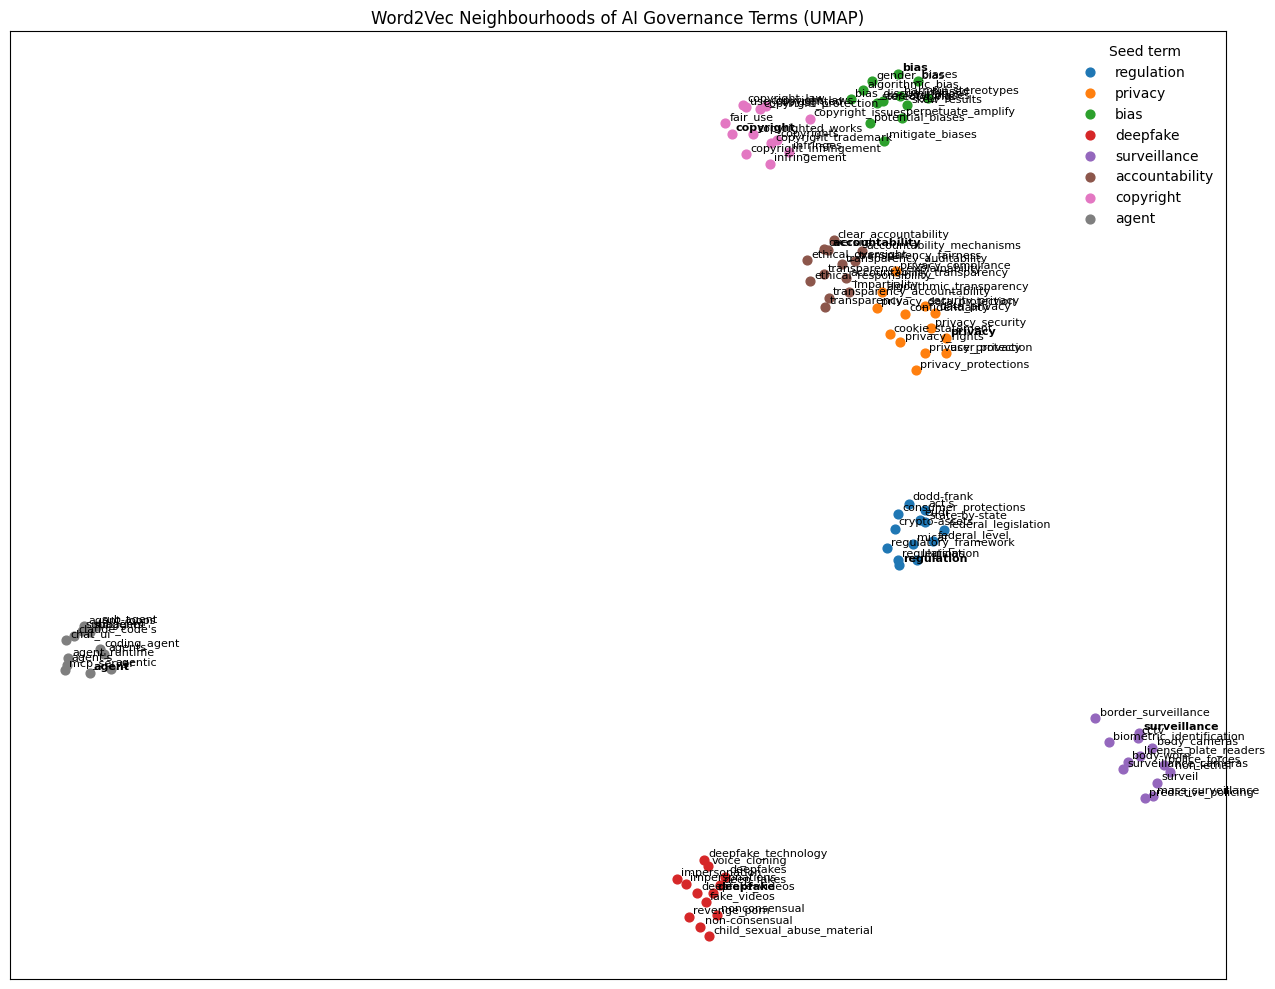

In [12]:
import umap

SEED_TERMS = ["regulation", "privacy", "bias", "deepfake", "surveillance", "accountability", "copyright", "agent"]

words, groups = [], []
for seed_term in SEED_TERMS:
    if seed_term not in w2v_model.wv.key_to_index:
        continue
    for word in [seed_term] + [w for w, _ in w2v_model.wv.most_similar(seed_term, topn=12)]:
        if word not in words:
            words.append(word)
            groups.append(seed_term)

word_coordinates = umap.UMAP(
    n_neighbors=10, min_dist=0.3, metric="cosine", random_state=SEED
).fit_transform(np.vstack([w2v_model.wv[word] for word in words]))

fig, ax = plt.subplots(figsize=(13, 10))
colors = plt.get_cmap("tab10")

for i, seed_term in enumerate(SEED_TERMS):
    idx = [j for j, group in enumerate(groups) if group == seed_term]
    ax.scatter(word_coordinates[idx, 0], word_coordinates[idx, 1], color=colors(i), label=seed_term, s=40)
    for j in idx:
        ax.annotate(
            words[j], word_coordinates[j],
            fontsize=8, fontweight="bold" if words[j] == seed_term else "normal",
            xytext=(3, 3), textcoords="offset points"
        )

ax.set_title("Word2Vec Neighbourhoods of AI Governance Terms (UMAP)")
ax.legend(title="Seed term", frameon=False, loc="best")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
save_figure("word2vec_governance_terms_umap")
plt.show()

**Observations**

The map shows local neighbourhoods of selected seed terms. UMAP can suggest thematic overlaps, but distances between separate groups in two dimensions should not be treated as quantitative semantic evidence.


The next figure projects the document vectors of the Governance articles with exactly one Governance theme into two dimensions, separately for each representation. It shows visually how well each representation separates the four themes.

/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


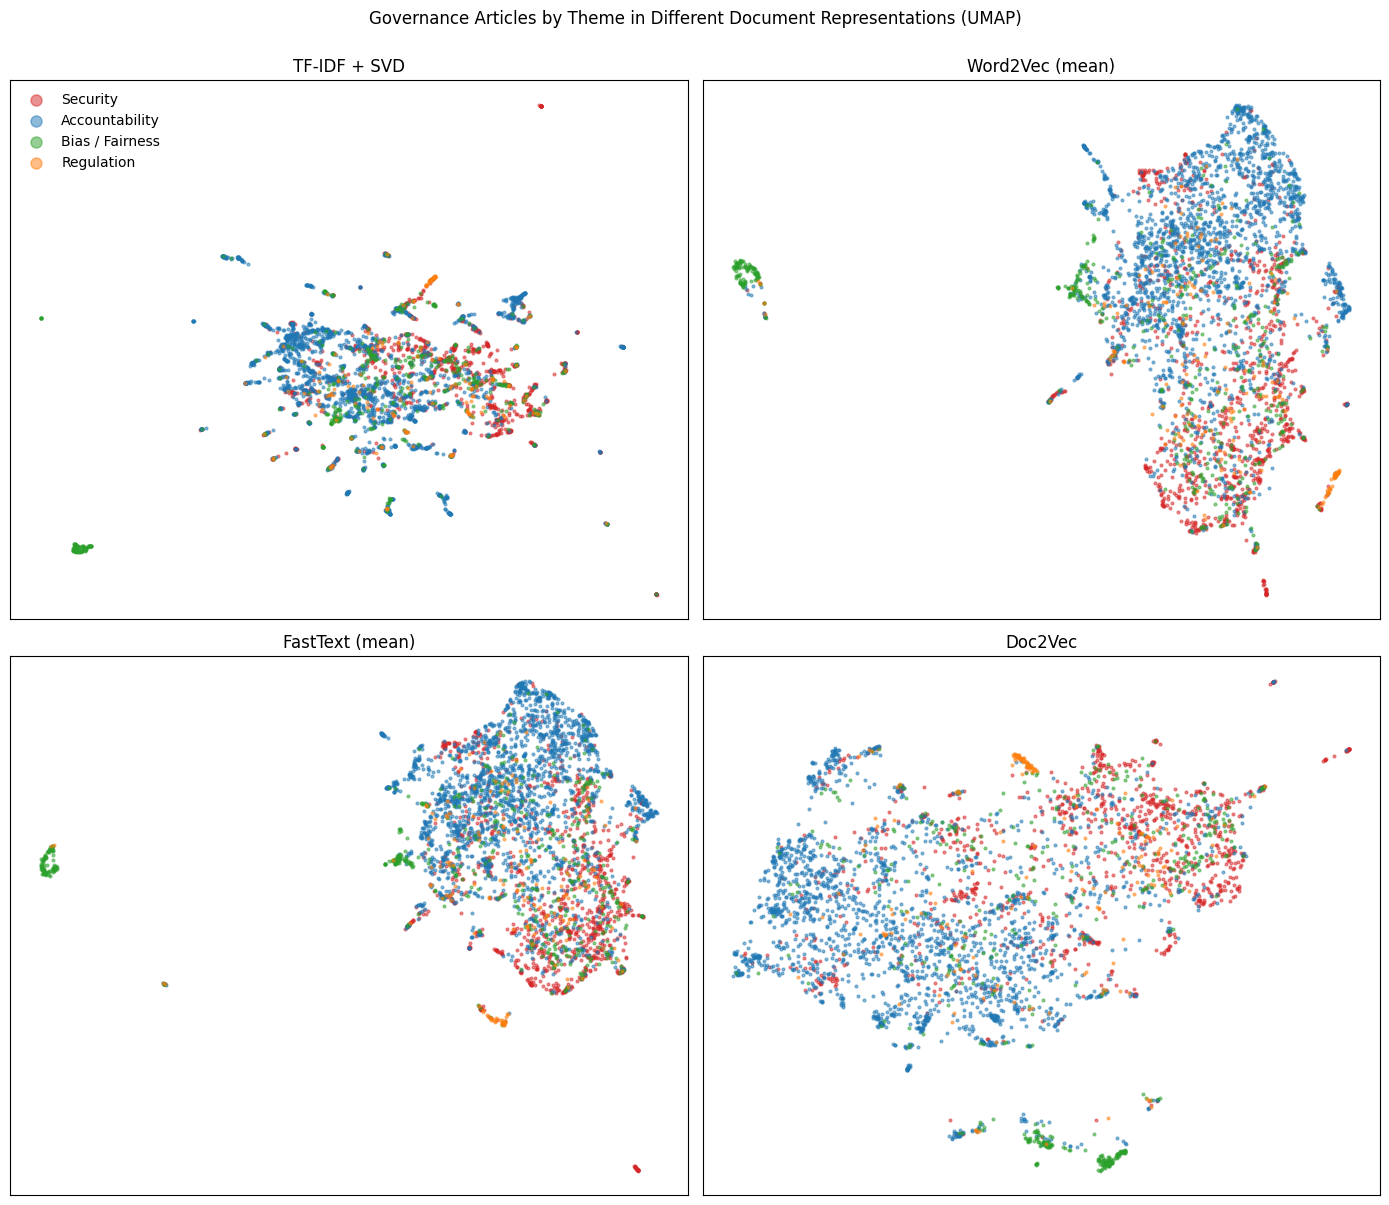

In [13]:
plot_sample = clustering_rng.choice(np.where(single_theme)[0], size=4000, replace=False)
theme_colors = {0: "tab:red", 1: "tab:blue", 2: "tab:green", 3: "tab:orange"}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, matrix) in zip(axes.ravel(), doc_vectors.items()):
    coordinates = umap.UMAP(
        n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED
    ).fit_transform(normalize(matrix[plot_sample]))
    labels = single_theme_label[plot_sample]
    for theme_index, theme in enumerate(GOVERNANCE_THEMES):
        mask = labels == theme_index
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=4, alpha=0.5,
                   color=theme_colors[theme_index], label=THEME_LABELS[theme])
    ax.set_title(REPRESENTATION_NAMES[name])
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].legend(markerscale=4, frameon=False)
fig.suptitle("Governance Articles by Theme in Different Document Representations (UMAP)", y=1.0)

plt.tight_layout()
save_figure("document_representations_umap")
plt.show()

**Observations**

Compare the coloured theme overlap with the silhouette table. Similar-looking article groups can reflect source-specific vocabulary or repeated formats as well as the Governance theme.


### 2.8 Semantic Shift of Governance Terms Over Time

Stage 1 showed that the Governance discourse shifted toward AI agents and deployment-oriented topics during 2026. To examine whether this shift is also visible in word meaning, two additional Word2Vec models are trained on the two halves of the observation period:

- **Period 1:** September 2024 – August 2025
- **Period 2:** September 2025 – August 2026

For selected terms, the nearest neighbours in both periods are compared. The overlap of the 20 nearest neighbours (Jaccard similarity) measures how stable the context of a term is: a low overlap indicates that the term is used in different contexts in the two periods.

In [14]:
PERIODS = {
    "Period 1 (2024-09 – 2025-08)": ("2024-09-01", "2025-08-31"),
    "Period 2 (2025-09 – 2026-08)": ("2025-09-01", "2026-08-31")
}
SHIFT_TERMS = ["agent", "accountability", "regulation", "security", "safety", "governance", "copyright", "china"]

period_models = {}
for period, (start, end) in PERIODS.items():
    path = EMBEDDING_MODELS_DIR / f"word2vec_{start[:7]}_{end[:7]}.model"
    if path.exists():
        period_models[period] = Word2Vec.load(str(path))
        continue
    in_period = ((corpus["date"] >= start) & (corpus["date"] <= end) & (corpus["split"].isin(TRAINING_SPLITS))).values
    sentences = [sentence for i in np.where(in_period)[0] for sentence in article_sentences[i]]
    model = Word2Vec(sentences=sentences, **EMBEDDING_PARAMS)
    model.save(str(path))
    period_models[period] = model
    print(f"{period}: trained on {len(sentences):,} sentences")

model_1, model_2 = period_models.values()

shift_rows = []
for term in SHIFT_TERMS:
    if term not in model_1.wv.key_to_index or term not in model_2.wv.key_to_index:
        continue
    neighbours_1 = [w for w, _ in model_1.wv.most_similar(term, topn=20)]
    neighbours_2 = [w for w, _ in model_2.wv.most_similar(term, topn=20)]
    overlap = len(set(neighbours_1) & set(neighbours_2)) / len(set(neighbours_1) | set(neighbours_2))
    shift_rows.append({
        "Term": term,
        "Neighbour overlap (Jaccard)": round(overlap, 2),
        "Top neighbours – Period 1": ", ".join(neighbours_1[:6]),
        "Top neighbours – Period 2": ", ".join(neighbours_2[:6]),
        "New in Period 2": ", ".join([w for w in neighbours_2 if w not in neighbours_1][:6])
    })

semantic_shift = pd.DataFrame(shift_rows).sort_values("Neighbour overlap (Jaccard)")
semantic_shift.to_csv(RESULTS_DIR / "semantic_shift.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(semantic_shift)

,Term,Neighbour overlap (Jaccard),Top neighbours – Period 1,Top neighbours – Period 2,New in Period 2
0,agent,0.05,"agents, ai_agents, multi-agent, ambient_agents, mcp_client, agentic","agents, subagent, sub-agent, agent's, coding_agent, agent_loop","subagent, sub-agent, agent's, agent_loop, a2h, tool_invocation"
4,safety,0.14,"safety_measures, safety_reliability, vehicle_safety, ensuring_safety, functional_safety, subcards","safety_reliability, safety_standards, vehicle_safety, occupational_health, ensuring_safety, privacy_compliance","occupational_health, privacy_compliance, reliability, ethical_legal, sotif, safety_regulations"
5,governance,0.21,"risk_compliance_grc, governance_framework, governance_structures, governance_policies, governance_frameworks, robust_governance","governance_frameworks, governance_framework, governance_policies, centralized_governance, governance_observability, clear_ownership","centralized_governance, clear_ownership, privacy_compliance, compliance_exercise, architectural_principles, clear_accountability"
2,regulation,0.25,"regulations, legislation, regulatory_framework, consumer_protections, federal_regulation, legal_framework","regulatory_framework, act's, eu_regulation, crypto-assets, consumer_protection, regulation_eu","act's, eu_regulation, crypto-assets, consumer_protection, competition_law, state-level"
1,accountability,0.29,"transparency_fairness, transparency_accountability, accountability_transparency, oversight, fairness_accountability, transparency","decision_rights, clear_accountability, oversight, transparency_accountability, transparency_fairness, transparency_explainability","decision_rights, micromanagement, independent_oversight, escalation_paths, establishing_clear, high-stakes_decisions"
3,security,0.29,"cybersecurity, security_posture, identity_management, security_compliance, security_measures, security_controls","cybersecurity, security_posture, vulnerability_management, posture_management, endpoint_protection, operations_center_soc","posture_management, operations_center_soc, threat_detection, endpoint_security, siem, cyber_security"
6,copyright,0.38,"fair_use, copyright_law, copyright_infringement, copyrights, copyright_protection, dmca","copyrights, copyright_law, infringement, infringing, copyright_trademark, fair_use","infringing, copyright_trademark, getty, defamation, journalistic, record_labels"
7,china,0.38,"beijing, chinese, china's, chinese_government, chinese_companies, rest_world","beijing, china's, chinese, taiwan, united_states_china, xi","xi, north_korea, beijing's, chinese_communist_party, rare_earths, pyongyang"


**Observations**

The lowest neighbour overlap indicates the largest change in local vocabulary in this run. Read the listed new neighbours to interpret the change; frequency, random initialization and source mix can also change neighbourhoods.


## 3. Baseline Classifiers for the Governance Themes

### 3.1 Task Definition and Evaluation Protocol

The extrinsic task is **multi-label classification**: for each Governance article, predict which of the four Governance themes apply. The labels come from the curated tag mapping of Stage 1.

All models follow the same protocol:

1. Train on the training split (9,062 articles).
2. Choose one decision threshold per theme on the validation split, maximizing the F1 score of that theme. This compensates for class imbalance in the same way for every model.
3. Report the final scores on the test split, which no model has seen during training or threshold selection.

Metrics: **F1 per theme**, **micro-F1** (all decisions pooled; dominated by frequent themes) and **macro-F1** (unweighted average over the four themes; sensitive to the rare Regulation theme).

As baselines, one logistic-regression classifier per theme is trained on each of the four document representations from Section 2.3. In addition, the classical **full TF-IDF** representation (all 50,000 terms, without dimensionality reduction) is used as a fifth baseline, because sparse TF-IDF with a linear classifier is known to be a strong reference for text classification.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

y_all = gov[GOVERNANCE_THEMES].astype(int).values
split_masks = {name: gov_split == name for name in ["train", "validation", "test"]}
y = {name: y_all[mask] for name, mask in split_masks.items()}


def tune_thresholds(y_true, scores):
    """One threshold per theme that maximizes the validation F1 of that theme."""
    candidates = np.linspace(0.05, 0.95, 91)
    return np.array([
        candidates[np.argmax([f1_score(y_true[:, k], scores[:, k] >= t, zero_division=0) for t in candidates])]
        for k in range(y_true.shape[1])
    ])


def evaluate(y_true, scores, thresholds):
    predictions = (scores >= thresholds).astype(int)
    result = {THEME_LABELS[theme]: f1_score(y_true[:, k], predictions[:, k], zero_division=0)
              for k, theme in enumerate(GOVERNANCE_THEMES)}
    result["Micro-F1"] = f1_score(y_true, predictions, average="micro", zero_division=0)
    result["Macro-F1"] = f1_score(y_true, predictions, average="macro", zero_division=0)
    return result  # Keep full precision for validation-based selection


classification_results = {}
classification_details = {}
classification_validation_results = {}
classification_thresholds = {}
classification_models = {}
BASELINE_KEYS = {}

REPRESENTATION_NAMES["tfidf_full"] = "TF-IDF (full)"
baseline_inputs = {"tfidf_full": tfidf.transform(gov_tokens), **doc_vectors}

for name, matrix in baseline_inputs.items():
    model_name = REPRESENTATION_NAMES[name] + " + LogReg"
    classifiers = []
    start_time = time.perf_counter()
    X = {split: matrix[mask] for split, mask in split_masks.items()}
    scores = {"validation": np.zeros_like(y["validation"], dtype=float),
              "test": np.zeros_like(y["test"], dtype=float)}
    for k in range(len(GOVERNANCE_THEMES)):
        classifier = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)
        classifier.fit(X["train"], y["train"][:, k])
        classifiers.append(classifier)
        for split in scores:
            scores[split][:, k] = classifier.predict_proba(X[split])[:, 1]
    thresholds = tune_thresholds(y["validation"], scores["validation"])
    classification_results[model_name] = evaluate(y["test"], scores["test"], thresholds)
    classification_validation_results[model_name] = evaluate(y["validation"], scores["validation"], thresholds)
    classification_thresholds[model_name] = thresholds
    classification_models[model_name] = classifiers
    BASELINE_KEYS[model_name] = name
    classification_details[REPRESENTATION_NAMES[name] + " + LogReg"] = {
        "training_seconds": round(time.perf_counter() - start_time, 1)
    }

baseline_results = pd.DataFrame(classification_results).T
baseline_results.to_csv(RESULTS_DIR / "baseline_classification_results.csv")

display(baseline_results)

def baseline_features(model_name, documents):
    key = BASELINE_KEYS[model_name]
    if key == "tfidf_full":
        return tfidf.transform(documents)
    if key == "tfidf_svd":
        return svd.transform(tfidf.transform(documents))
    if key == "word2vec_mean":
        return np.vstack([mean_vector(w2v_model.wv, tokens) for tokens in documents])
    if key == "fasttext_mean":
        return np.vstack([mean_vector(fasttext_model.wv, tokens) for tokens in documents])
    return np.vstack([d2v_model.infer_vector(tokens, epochs=20) for tokens in documents])


def predict_baseline(model_name, documents):
    features = baseline_features(model_name, documents)
    return np.column_stack([head.predict_proba(features)[:, 1]
                            for head in classification_models[model_name]])

joblib.dump(classification_models, EMBEDDING_MODELS_DIR / "theme_classifiers.joblib")


,Security,Accountability,Bias / Fairness,Regulation,Micro-F1,Macro-F1
TF-IDF (full) + LogReg,0.772003,0.833405,0.657471,0.691358,0.774053,0.738559
TF-IDF + SVD + LogReg,0.752078,0.819016,0.574642,0.648910,0.741448,0.698661
Word2Vec (mean) + LogReg,0.733379,0.817140,0.574493,0.534188,0.727699,0.664800
FastText (mean) + LogReg,0.741201,0.817241,0.592675,0.528736,0.728043,0.669963
Doc2Vec + LogReg,0.754848,0.822121,0.570194,0.590389,0.739579,0.684388


['/Users/henrik/Documents/CTL/outputs/models/stage2/train_only_df7049374b50/theme_classifiers.joblib']

**Observations**

Compare validation and test performance per theme rather than only one overall score. Sparse TF-IDF preserves specific legal and regulatory terms, whereas averaging vectors can dilute a rare but informative term. The selected model is determined later from validation Macro-F1 across all model families.


## 4. Fine-Tuning Compact Open Models with QLoRA

### 4.1 Approach

Two models of the same family but different size are fine-tuned for the Governance classification task:

| Model | Parameters | Role |
|---|---|---|
| **Qwen3-1.7B** | 1.7 billion | smaller model |
| **Qwen3-4B** | 4.0 billion | larger model of the same family |

Both checkpoints belong to the Qwen3 family. This is a useful practical size comparison, but different pretrained checkpoints and one run each do not isolate a causal effect of size.

**QLoRA** makes fine-tuning feasible on an 8 GB laptop GPU:

- The pretrained weights are loaded in **4-bit precision** (NF4 quantization) and stay frozen.
- Small trainable **LoRA adapters** (rank 16) are added to all attention and MLP projections, together with a new classification head with four outputs. Only about 1% of the parameters are trained.
- **Gradient checkpointing** trades computation for memory.

The classification head predicts the four Governance themes independently (multi-label, sigmoid outputs). The loss is binary cross-entropy with positive-class weights, analogous to the class-weighted baselines, and the decision thresholds are tuned on the validation split as in Section 3.

**Input length.** A benchmark on this GPU showed about 0.4 s per training example for Qwen3-1.7B at 256 tokens and 0.8 s at 512 tokens. To keep the training time of both models feasible (about one and 2.5 hours for one epoch), the input is limited to **256 tokens from title + article text** of each article. This is a deliberate trade-off: the baselines see the complete article text, while the language models see only its beginning.

In [16]:
import gc

from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from torch.utils.data import DataLoader
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
    get_linear_schedule_with_warmup
)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

QLORA_CONFIG = {
    "max_length": LLM_MAX_LENGTH,
    "epochs": 1,
    "batch_size": 4,
    "gradient_accumulation": 4,     # effective batch size 16
    "learning_rate": 2e-4,
    "warmup_ratio": 0.05,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
}

LLM_MODELS = {
    "Qwen3-1.7B": "Qwen/Qwen3-1.7B",
    "Qwen3-4B": "Qwen/Qwen3-4B"
}

gov_texts = (gov["title"] + ". " + gov["content_text"]).tolist()
split_texts = {split: [t for t, m in zip(gov_texts, mask) if m] for split, mask in split_masks.items()}

positive_weight = torch.tensor(
    (len(y["train"]) - y["train"].sum(axis=0)) / y["train"].sum(axis=0), dtype=torch.float
)


COMPUTE_DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
                 else torch.float16)


def load_quantized_classifier(model_id):
    if not torch.cuda.is_available():
        raise RuntimeError("New QLoRA training/inference requires CUDA; use the saved GPU results on this CPU machine.")
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.padding_side = "right"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=len(GOVERNANCE_THEMES),
        problem_type="multi_label_classification",
        quantization_config=BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=COMPUTE_DTYPE
        ),
        device_map={"": 0},
        dtype=COMPUTE_DTYPE
    )
    model.config.pad_token_id = tokenizer.pad_token_id
    return tokenizer, model


def batches(texts, tokenizer, batch_size, labels=None, shuffle=False):
    order = np.random.default_rng(SEED).permutation(len(texts)) if shuffle else np.arange(len(texts))
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        encoded = tokenizer(
            [texts[i] for i in idx], truncation=True, max_length=QLORA_CONFIG["max_length"],
            padding=True, return_tensors="pt"
        ).to(0)
        yield encoded, (torch.tensor(labels[idx], dtype=torch.float).to(0) if labels is not None else None)


@torch.no_grad()
def predict(model, tokenizer, texts, batch_size=16, return_embeddings=False):
    """Sigmoid scores (and optionally last-token hidden states) for a list of texts."""
    model.eval()
    scores, embeddings = [], []
    for encoded, _ in batches(texts, tokenizer, batch_size):
        with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
            output = model(**encoded, output_hidden_states=return_embeddings)
        scores.append(torch.sigmoid(output.logits.float()).cpu().numpy())
        if return_embeddings:
            last_token = encoded["attention_mask"].sum(dim=1) - 1
            hidden = output.hidden_states[-1][torch.arange(len(last_token), device=last_token.device), last_token]
            embeddings.append(hidden.float().cpu().numpy())
    scores = np.vstack(scores)
    return (scores, np.vstack(embeddings)) if return_embeddings else scores

### 4.1a Long articles: input coverage and a bounded chunking experiment

The QLoRA classifiers currently see the title and at most 256 tokens, whereas the classical representations use the article text. We measure the resulting coverage with the actual Qwen tokenizer, rather than treating words as model tokens. Word2Vec/FastText already use sentence contexts; the longest preprocessed article contains 5,395 tokens, so none reaches Doc2Vec's 10,000-token limit. Additional chunking is therefore most relevant to the Qwen classifiers.

Processing every overlapping window would require about 10.75 sequences per Governance article with 256-token windows and 32-token overlap. To keep an optional experiment manageable, we retain at most four windows spread over each article. This improves input coverage but still does not guarantee complete coverage or better F1. Article IDs are split before constructing windows, and scores are aggregated back to one row per article.



,tokens,prefix_coverage,chunk_count,chunk_coverage
count,12946.000,12946.000,12946.0,12946.000
mean,2327.433,0.150,4.0,0.568
std,1681.818,0.066,0.0,0.227
min,791.000,0.018,4.0,0.074
25%,1261.000,0.095,4.0,0.381
50%,1694.500,0.151,4.0,0.604
75%,2690.750,0.203,4.0,0.787
max,13874.000,0.324,4.0,1.000


Truncated at 256 tokens: 100.0%
Mean text coverage: prefix 15.0%; bounded chunks 56.8%


,Mean article coverage (%),Token-weighted coverage (%),Sequences per article
Input policy,,,
Prefix 256,14.96,11.00,1.00
Prefix 512,29.91,22.00,1.00
Up to four 256-token chunks,56.79,42.62,4.00
All 256-token chunks,100.00,100.00,10.75


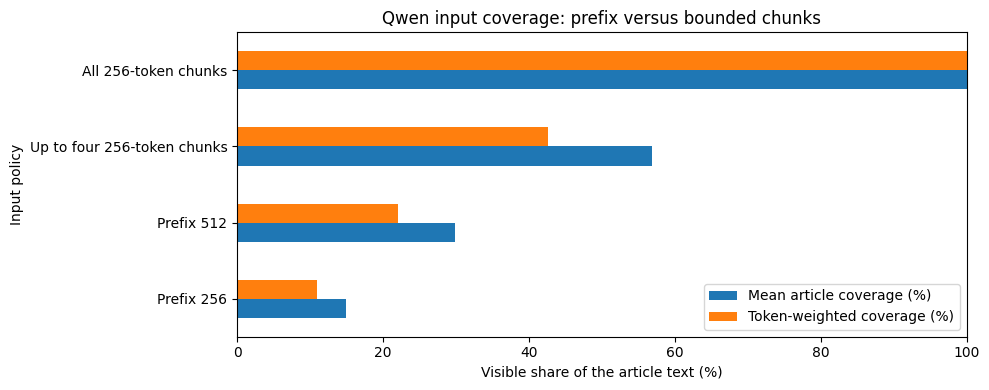

In [17]:
CHUNK_CONFIG = {"max_length": 256, "overlap": 32, "max_chunks": 4}
TOKENIZER_ID = "Qwen/Qwen3-1.7B"
tokenizer_dir = MODELS_DIR / "qwen3_tokenizer"
audit_tokenizer = AutoTokenizer.from_pretrained(str(tokenizer_dir) if tokenizer_dir.exists() else TOKENIZER_ID)
if not tokenizer_dir.exists():
    audit_tokenizer.save_pretrained(tokenizer_dir)


def token_windows(ids, max_length=256, overlap=32, max_chunks=4):
    """Keep up to four windows spread across one document; never change its split."""
    if max_length < 1 or not 0 <= overlap < max_length or max_chunks < 1:
        raise ValueError("Invalid chunk size, overlap or maximum number of chunks.")
    starts = list(range(0, max(1, len(ids) - max_length + 1), max_length - overlap))
    if starts[-1] + max_length < len(ids):
        starts.append(len(ids) - max_length)
    selected = np.linspace(0, len(starts) - 1, min(max_chunks, len(starts))).round().astype(int)
    starts = [starts[i] for i in selected]
    windows = [ids[start:start + max_length] for start in starts]
    covered, previous_end = 0, 0
    for start, window in zip(starts, windows):
        end = start + len(window)
        covered += max(0, end - max(start, previous_end))
        previous_end = max(previous_end, end)
    return windows, covered / max(1, len(ids))


def pool_chunk_scores(scores, owners, n_documents, method):
    """Return one multi-label score row per article, not one row per chunk."""
    owners, scores = np.asarray(owners), np.asarray(scores)
    counts = np.bincount(owners, minlength=n_documents)
    if scores.ndim != 2 or len(scores) != len(owners) or np.any(counts == 0):
        raise ValueError("Every document needs at least one matching chunk score.")
    if method == "mean":
        pooled = np.zeros((n_documents, scores.shape[1]))
        np.add.at(pooled, owners, scores)
        return pooled / counts[:, None]
    if method == "max":
        pooled = np.full((n_documents, scores.shape[1]), -np.inf)
        np.maximum.at(pooled, owners, scores)
        return pooled
    raise ValueError("Pooling must be mean or max.")


length_path = STAGE2_DATA_DIR / "qwen_token_lengths.csv"
length_meta_path = length_path.with_suffix(".json")
length_config = {"data_fingerprint": DATA_FINGERPRINT, "tokenizer": TOKENIZER_ID,
                 "prefix_max_length": QLORA_CONFIG["max_length"], **CHUNK_CONFIG}
if length_path.exists() and length_meta_path.exists() and json.loads(length_meta_path.read_text()) == length_config:
    length_audit = pd.read_csv(length_path)
    if length_audit["record_id"].tolist() != gov["record_id"].tolist():
        raise ValueError("Token-length cache has a different article order.")
else:
    rows = []
    for start in range(0, len(gov_texts), 128):
        batch = audit_tokenizer(gov_texts[start:start + 128], add_special_tokens=False, truncation=False)
        for offset, ids in enumerate(batch["input_ids"]):
            windows, coverage = token_windows(ids, **CHUNK_CONFIG)
            rows.append({"record_id": gov.iloc[start + offset]["record_id"], "tokens": len(ids),
                         "prefix_coverage": min(len(ids), QLORA_CONFIG["max_length"]) / max(1, len(ids)),
                         "chunk_count": len(windows), "chunk_coverage": coverage})
    length_audit = pd.DataFrame(rows)
    length_audit.to_csv(length_path, index=False)
    length_meta_path.write_text(json.dumps(length_config, indent=2))
display(length_audit[["tokens", "prefix_coverage", "chunk_count", "chunk_coverage"]].describe().round(3))
print(f"Truncated at {QLORA_CONFIG['max_length']} tokens: {(length_audit['tokens'] > QLORA_CONFIG['max_length']).mean():.1%}")
print(f"Mean text coverage: prefix {length_audit['prefix_coverage'].mean():.1%}; bounded chunks {length_audit['chunk_coverage'].mean():.1%}")


# Compare coverage and sequence counts, not unmeasured F1 improvements.
lengths = length_audit["tokens"].to_numpy()
full_windows = 1 + np.ceil(np.maximum(lengths - 256, 0) / 224).astype(int)
policies = [
    ("Prefix 256", np.minimum(lengths, 256) / lengths, np.ones(len(lengths))),
    ("Prefix 512", np.minimum(lengths, 512) / lengths, np.ones(len(lengths))),
    ("Up to four 256-token chunks", length_audit["chunk_coverage"].to_numpy(), length_audit["chunk_count"].to_numpy()),
    ("All 256-token chunks", np.ones(len(lengths)), full_windows),
]
coverage_comparison = pd.DataFrame([
    {"Input policy": name, "Mean article coverage (%)": 100 * coverage.mean(),
     "Token-weighted coverage (%)": 100 * np.average(coverage, weights=lengths),
     "Sequences per article": counts.mean()}
    for name, coverage, counts in policies
]).set_index("Input policy")
coverage_comparison.to_csv(RESULTS_DIR / "input_coverage_comparison.csv")
display(coverage_comparison.round(2))
coverage_comparison.iloc[:, :2].plot.barh(figsize=(10, 4), xlim=(0, 100))
plt.xlabel("Visible share of the article text (%)")
plt.title("Qwen input coverage: prefix versus bounded chunks")
plt.tight_layout()
save_figure("input_coverage_chunking")
plt.show()


**Interpretation of the CPU run (25 October 2026).** The 256-token prefix retains **14.96%** of an article on average. Four selected windows cover **56.79%** (**+41.84 percentage points**, about **3.8 times** the visible text), using four input sequences per article instead of one. This measures input coverage, not a classification improvement. **The chunk-inference experiment was not executed in this CPU run**, so its effect on F1 is still unknown; the reported Qwen scores remain the prefix baselines. The current full-text TF-IDF test Macro-F1 of 0.739 comes from the revised preprocessing/evaluation and must not be attributed to chunking. A CUDA run with the adapters is needed to compare prefix and chunk predictions, choosing pooling and thresholds on validation before reporting test F1.

### 4.2 Training and Evaluation

For each model, the following steps are performed and cached:

1. Load the model in 4-bit precision and add the LoRA adapters.
2. Train for one epoch on the training split, recording training time and peak GPU memory.
3. Predict the validation and test splits and measure the inference speed.
4. Extract the last-token hidden states of the test articles from the fine-tuned model and from the original model (adapters disabled) for the representation comparison in Section 5.

The trained LoRA adapters (a few dozen megabytes) are saved in `outputs/models/stage2/`; re-running the notebook loads the saved results instead of retraining.
Saved reference runs retain their original training recipe. The code below fixes the final partial gradient-accumulation step for future CUDA training; existing cached scores are not presented as results of that correction.


In [18]:
def finetune_qlora(name, model_id):
    adapter_dir = MODELS_DIR / f"qlora_{name}"
    results_path = RESULTS_DIR / f"qlora_{name}_predictions.npz"
    stats_path = RESULTS_DIR / f"qlora_{name}_stats.json"
    config_id = json.dumps({"model": model_id, **QLORA_CONFIG}, sort_keys=True)

    if results_path.exists() and stats_path.exists():
        stats = json.loads(stats_path.read_text())
        if stats.get("config_id") == config_id:
            if stats.get("data_fingerprint") is None:
                reference = pd.read_csv(RESULTS_DIR / "qlora_reference_splits.csv")
                for split in ["train", "validation", "test"]:
                    assert np.array_equal(reference.loc[reference["split"] == split, "record_id"].values,
                                          gov.loc[split_masks[split], "record_id"].values), "QLoRA cache split/order mismatch"
                snapshot = json.loads((RESULTS_DIR / "qlora_reference_snapshot.json").read_text())
                if snapshot["data_fingerprint"] != DATA_FINGERPRINT:
                    raise ValueError("Legacy QLoRA reference no longer matches the reviewed input snapshot")
            elif stats["data_fingerprint"] != DATA_FINGERPRINT:
                raise ValueError("QLoRA cache belongs to different article texts")
            cached = dict(np.load(results_path))
            for split in ["validation", "test"]:
                assert cached[f"{split}_scores"].shape == y[split].shape
                assert np.isfinite(cached[f"{split}_scores"]).all()
            stats.setdefault("run_source", "GPU reference, original prefix-256 recipe")
            if "training_recipe" not in stats:
                stats["training_recipe"] = "original GPU run; not rerun during this review"
            print(f"{name}: results loaded from cache.")
            return stats, cached

    if not torch.cuda.is_available():
        raise RuntimeError("A matching QLoRA cache is missing. Run this training cell on CUDA.")
    torch.manual_seed(SEED)
    torch.cuda.reset_peak_memory_stats()
    tokenizer, model = load_quantized_classifier(model_id)
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(
        task_type="SEQ_CLS",
        r=QLORA_CONFIG["lora_r"],
        lora_alpha=QLORA_CONFIG["lora_alpha"],
        lora_dropout=QLORA_CONFIG["lora_dropout"],
        target_modules=QLORA_CONFIG["target_modules"]
    ))
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=QLORA_CONFIG["learning_rate"])
    steps_per_epoch = int(np.ceil(len(split_texts["train"]) / QLORA_CONFIG["batch_size"]
                                  / QLORA_CONFIG["gradient_accumulation"]))
    total_steps = steps_per_epoch * QLORA_CONFIG["epochs"]
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(QLORA_CONFIG["warmup_ratio"] * total_steps), total_steps
    )
    loss_function = torch.nn.BCEWithLogitsLoss(pos_weight=positive_weight.to(0))

    scaler = torch.amp.GradScaler("cuda", enabled=COMPUTE_DTYPE == torch.float16)
    model.train()
    start_time = time.perf_counter()
    step, running_loss = 0, []

    n_batches = int(np.ceil(len(y["train"]) / QLORA_CONFIG["batch_size"]))
    optimizer.zero_grad()
    for epoch in range(QLORA_CONFIG["epochs"]):
        for batch_number, (encoded, labels) in enumerate(
            batches(split_texts["train"], tokenizer, QLORA_CONFIG["batch_size"], y["train"], shuffle=True), start=1
        ):
            with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
                logits = model(**encoded).logits
            batch_loss = loss_function(logits.float(), labels)
            # Weight the final partial accumulation group by its actual examples.
            group_start = ((batch_number - 1) // QLORA_CONFIG["gradient_accumulation"]
                           * QLORA_CONFIG["gradient_accumulation"] * QLORA_CONFIG["batch_size"])
            group_examples = min(QLORA_CONFIG["gradient_accumulation"] * QLORA_CONFIG["batch_size"],
                                 len(y["train"]) - group_start)
            loss = batch_loss * len(labels) / group_examples
            scaler.scale(loss).backward()
            running_loss.append(batch_loss.item())

            if batch_number % QLORA_CONFIG["gradient_accumulation"] == 0 or batch_number == n_batches:
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= old_scale:  # Do not advance the schedule on an overflow-skipped update
                    scheduler.step()
                    step += 1
                optimizer.zero_grad()
                if step > 0 and (step % 50 == 0 or batch_number == n_batches):
                    elapsed = time.perf_counter() - start_time
                    print(f"{name} | step {step}/{total_steps} | loss {np.mean(running_loss[-200:]):.4f} | "
                          f"{elapsed / 60:.1f} min elapsed | ~{elapsed / step * (total_steps - step) / 60:.0f} min left")

    training_seconds = time.perf_counter() - start_time
    peak_memory_gb = torch.cuda.max_memory_allocated() / 1024 ** 3
    model.save_pretrained(adapter_dir)

    # Predictions and inference speed
    start_time = time.perf_counter()
    validation_scores = predict(model, tokenizer, split_texts["validation"])
    inference_seconds_per_1000 = (time.perf_counter() - start_time) / len(split_texts["validation"]) * 1000
    test_scores, test_embeddings_finetuned = predict(model, tokenizer, split_texts["test"], return_embeddings=True)
    with model.disable_adapter():
        _, test_embeddings_base = predict(model, tokenizer, split_texts["test"], return_embeddings=True)

    stats = {
        "config_id": config_id,
        "data_fingerprint": DATA_FINGERPRINT,
        "training_recipe": "partial_accumulation_fixed_v2",
        "run_source": "CUDA run, corrected partial accumulation",
        "model_id": model_id,
        "total_parameters": int(total),
        "trainable_parameters": int(trainable),
        "training_minutes": round(training_seconds / 60, 1),
        "peak_gpu_memory_gb": round(peak_memory_gb, 2),
        "inference_seconds_per_1000": round(inference_seconds_per_1000, 1),
        "final_training_loss": round(float(np.mean(running_loss[-200:])), 4)
    }
    predictions = {
        "validation_scores": validation_scores,
        "test_scores": test_scores,
        "test_embeddings_finetuned": test_embeddings_finetuned,
        "test_embeddings_base": test_embeddings_base
    }
    np.savez_compressed(results_path, **predictions)
    stats_path.write_text(json.dumps(stats, indent=2))

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return stats, predictions


llm_stats, llm_predictions = {}, {}
for name, model_id in LLM_MODELS.items():
    llm_stats[name], llm_predictions[name] = finetune_qlora(name, model_id)

for name in LLM_MODELS:
    thresholds = tune_thresholds(y["validation"], llm_predictions[name]["validation_scores"])
    classification_results[f"{name} (QLoRA)"] = evaluate(y["test"], llm_predictions[name]["test_scores"], thresholds)
    classification_validation_results[f"{name} (QLoRA)"] = evaluate(
        y["validation"], llm_predictions[name]["validation_scores"], thresholds)
    classification_thresholds[f"{name} (QLoRA)"] = thresholds

display(pd.DataFrame(llm_stats).T.drop(columns=["config_id", "total_parameters"]))

validation_results = pd.DataFrame(classification_validation_results).T
validation_results.to_csv(RESULTS_DIR / "validation_classification_results.csv")
BEST_MODEL = validation_results["Macro-F1"].idxmax()
print(f"Model selected only on validation Macro-F1: {BEST_MODEL}")
display(validation_results.sort_values("Macro-F1", ascending=False))


Qwen3-1.7B: results loaded from cache.
Qwen3-4B: results loaded from cache.


,model_id,trainable_parameters,training_minutes,peak_gpu_memory_gb,inference_seconds_per_1000,final_training_loss,run_source,training_recipe
Qwen3-1.7B,Qwen/Qwen3-1.7B,17440768,117.7,2.59,232.8,0.6771,"GPU reference, original prefix-256 recipe",original GPU run; not rerun during this review
Qwen3-4B,Qwen/Qwen3-4B,33040384,150.8,5.16,1152.7,0.6669,"GPU reference, original prefix-256 recipe",original GPU run; not rerun during this review


Model selected only on validation Macro-F1: TF-IDF (full) + LogReg


,Security,Accountability,Bias / Fairness,Regulation,Micro-F1,Macro-F1
TF-IDF (full) + LogReg,0.771881,0.842925,0.661417,0.613208,0.771626,0.722358
TF-IDF + SVD + LogReg,0.745833,0.824569,0.597771,0.584906,0.740627,0.688270
Qwen3-1.7B (QLoRA),0.730044,0.813451,0.557089,0.553191,0.730838,0.663444
Doc2Vec + LogReg,0.738376,0.825436,0.566845,0.518337,0.730495,0.662249
Qwen3-4B (QLoRA),0.732646,0.813366,0.544177,0.554348,0.722170,0.661134
FastText (mean) + LogReg,0.731640,0.819601,0.568257,0.500000,0.719136,0.654875
Word2Vec (mean) + LogReg,0.732375,0.819616,0.572104,0.487069,0.723612,0.652791


### 4.3 Optional chunk-inference ablation

The optional experiment compares the existing prefix-trained classifier with inference over several windows. It does **not** retrain QLoRA or pretend that article-level themes are correct labels for every individual passage. The best Qwen model, pooling method and thresholds are chosen using validation data; test labels are used only for the final comparison. Results and input settings are cached separately from the original prefix predictions. The experiment is disabled by default because it requires CUDA and the saved adapters. No chunking F1 is reported until it has actually run.

Tokenizer overlap/overflow reference: https://huggingface.co/docs/transformers/main/main_classes/tokenizer
Doc2Vec implementation reference: https://github.com/piskvorky/gensim/blob/4.4.0/gensim/models/doc2vec_inner.pyx


In [19]:

RUN_CHUNKING_EXPERIMENT = False


@torch.no_grad()
def predict_document_chunks(model, tokenizer, texts, batch_size=16):
    chunks, owners = [], []
    for owner, text in enumerate(texts):
        ids = tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"] or [tokenizer.eos_token_id]
        windows, _ = token_windows(ids, **CHUNK_CONFIG)
        chunks.extend(windows)
        owners.extend([owner] * len(windows))
    model.eval()
    chunk_scores = []
    for start in range(0, len(chunks), batch_size):
        encoded = tokenizer.pad([{"input_ids": ids} for ids in chunks[start:start + batch_size]],
                                padding=True, return_tensors="pt").to(0)
        with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
            logits = model(**encoded).logits
        chunk_scores.append(torch.sigmoid(logits.float()).cpu().numpy())
    scores = np.vstack(chunk_scores)
    return {method: pool_chunk_scores(scores, owners, len(texts), method) for method in ["mean", "max"]}


if RUN_CHUNKING_EXPERIMENT:
    validation_f1 = {name: f1_score(y["validation"], values["validation_scores"] >=
                     tune_thresholds(y["validation"], values["validation_scores"]), average="macro", zero_division=0)
                     for name, values in llm_predictions.items()}
    chunk_model = max(validation_f1, key=validation_f1.get)
    chunk_path = RESULTS_DIR / f"chunking_{chunk_model}_predictions.npz"
    chunk_meta_path = chunk_path.with_suffix(".json")
    chunk_meta = {"data_fingerprint": DATA_FINGERPRINT, "model": LLM_MODELS[chunk_model],
                  "training": QLORA_CONFIG, "chunking": CHUNK_CONFIG, "seed": SEED,
                  "ids": {split: gov.loc[split_masks[split], "record_id"].tolist() for split in ["validation", "test"]}}
    if chunk_path.exists() and chunk_meta_path.exists() and json.loads(chunk_meta_path.read_text()) == chunk_meta:
        chunk_predictions = dict(np.load(chunk_path))
    else:
        adapter_dir = MODELS_DIR / f"qlora_{chunk_model}"
        if not torch.cuda.is_available() or not adapter_dir.exists():
            raise RuntimeError("Chunk inference needs CUDA and the saved QLoRA adapters; no new scores were computed.")
        tokenizer, base_model = load_quantized_classifier(LLM_MODELS[chunk_model])
        model = PeftModel.from_pretrained(base_model, adapter_dir)
        chunk_predictions = {}
        for split in ["validation", "test"]:
            for method, scores in predict_document_chunks(model, tokenizer, split_texts[split]).items():
                chunk_predictions[f"{split}_{method}"] = scores
        np.savez_compressed(chunk_path, **chunk_predictions)
        chunk_meta_path.write_text(json.dumps(chunk_meta, indent=2))
        del model, base_model
        gc.collect()
        torch.cuda.empty_cache()
    chunk_thresholds = {method: tune_thresholds(y["validation"], chunk_predictions[f"validation_{method}"])
                        for method in ["mean", "max"]}
    pooling_validation = {method: f1_score(y["validation"], chunk_predictions[f"validation_{method}"] >=
                          chunk_thresholds[method], average="macro", zero_division=0) for method in chunk_thresholds}
    selected_pooling = max(pooling_validation, key=pooling_validation.get)
    print("Pooling chosen on validation only:", selected_pooling, pooling_validation)
    comparison = []
    for strategy, scores, thresholds in [
        ("prefix", llm_predictions[chunk_model]["test_scores"], tune_thresholds(y["validation"], llm_predictions[chunk_model]["validation_scores"])),
        (f"chunks ({selected_pooling})", chunk_predictions[f"test_{selected_pooling}"], chunk_thresholds[selected_pooling])]:
        comparison.append({"Model": chunk_model, "Input": strategy, **evaluate(y["test"], scores, thresholds)})
    chunk_comparison = pd.DataFrame(comparison)
    chunk_comparison.to_csv(RESULTS_DIR / "chunking_comparison.csv", index=False)
    display(chunk_comparison)
else:
    print("Chunking inference was not run. Current QLoRA F1 results use the 256-token article prefix.")


Chunking inference was not run. Current QLoRA F1 results use the 256-token article prefix.


**Observations**

The table contains the saved GPU training measurements. Trainable parameter counts refer to adapters and the classification head, not full fine-tuning. Peak allocated memory is a measurement for those runs, not a guarantee for every 8-GB GPU. Similar training losses do not by themselves establish equal generalization.


## 5. Comparative Evaluation

### 5.1 Classification Performance

All supervised heads use the same labelled article split. The table below reports test scores; the separate validation table selects the model used for insights. Theme thresholds are fitted on validation only. Classical representations additionally use unlabelled training text; Qwen uses its pretrained checkpoint and only the article prefix during the saved fine-tuning runs.


Validation-selected model: TF-IDF (full) + LogReg


,Security,Accountability,Bias / Fairness,Regulation,Micro-F1,Macro-F1
TF-IDF (full) + LogReg,0.772,0.833,0.657,0.691,0.774,0.739
TF-IDF + SVD + LogReg,0.752,0.819,0.575,0.649,0.741,0.699
Word2Vec (mean) + LogReg,0.733,0.817,0.574,0.534,0.728,0.665
FastText (mean) + LogReg,0.741,0.817,0.593,0.529,0.728,0.670
Doc2Vec + LogReg,0.755,0.822,0.570,0.590,0.740,0.684
Qwen3-1.7B (QLoRA),0.738,0.815,0.563,0.585,0.737,0.675
Qwen3-4B (QLoRA),0.738,0.820,0.544,0.556,0.727,0.664


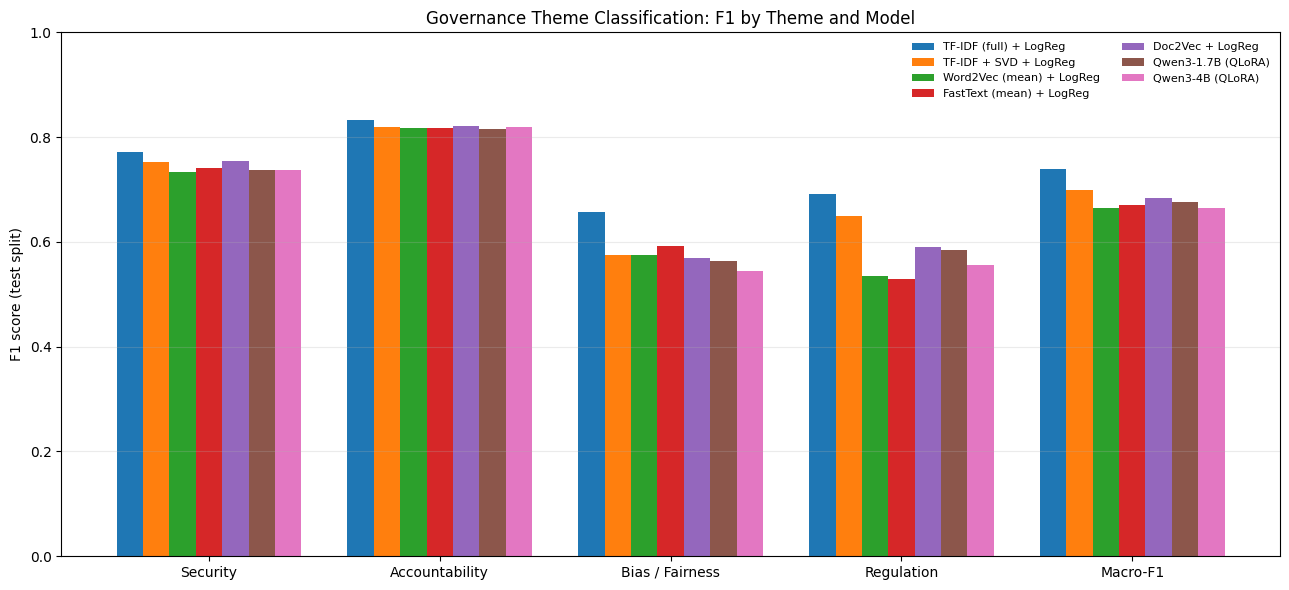

In [20]:
MODEL_ORDER = list(classification_results)

final_results = pd.DataFrame(classification_results).T.loc[MODEL_ORDER]
final_results.to_csv(RESULTS_DIR / "classification_results.csv")

print(f"Validation-selected model: {BEST_MODEL}")
display(final_results.style.highlight_max(axis=0, color="#cde8cd").format("{:.3f}"))

fig, ax = plt.subplots(figsize=(13, 6))
metrics = [THEME_LABELS[t] for t in GOVERNANCE_THEMES] + ["Macro-F1"]
bar_width = 0.8 / len(MODEL_ORDER)
x = np.arange(len(metrics))

for i, model_name in enumerate(MODEL_ORDER):
    ax.bar(x + i * bar_width, final_results.loc[model_name, metrics], width=bar_width, label=model_name)

ax.set_xticks(x + bar_width * (len(MODEL_ORDER) - 1) / 2)
ax.set_xticklabels(metrics)
ax.set_ylabel("F1 score (test split)")
ax.set_ylim(0, 1)
ax.set_title("Governance Theme Classification: F1 by Theme and Model")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("classification_f1_by_model")
plt.show()

**Observations**

The test table reports the final comparison; it is not used to select the model. Prefix-only Qwen versus full-text classical inputs is an important limitation. The length analysis quantifies this difference; only a measured chunk/longer-input experiment could establish whether it changes the ranking. A single run does not establish statistical significance.


### 5.2 Trade-offs: Size, Training Time, Hardware and Speed

Training includes representation learning and the classifier heads. CPU inference measures vectorization **plus all four classifier predictions**, starting from pre-tokenized articles; Qwen's saved inference timing includes tokenization and its forward pass. CPU and GPU results were measured on different systems and with different visible text lengths.

Classical parameter counts include the arrays optimized during training (including negative-sampling output weights) and the four heads. TF-IDF feature statistics and neural weights are different objects; these counts are descriptive size estimates, not a claim of equivalent capacity. GPU memory is the recorded peak allocation of the original GPU run.

For full TF-IDF, the parameter estimate counts the four linear classifier heads once; vocabulary and IDF statistics are feature metadata.


In [21]:
inference_sample = [gov_tokens[i] for i in np.where(split_masks["test"])[0][:1000]]


def seconds_per_1000(vectorize):
    start_time = time.perf_counter()
    vectorize(inference_sample)
    return round((time.perf_counter() - start_time) / len(inference_sample) * 1000, 1)


classical_inference = {
    name: seconds_per_1000(lambda docs, name=name: predict_baseline(name, docs))
    for name in classification_models
}

embedding_training = {
    "TF-IDF (full) + LogReg": training_times.get("TF-IDF", 0),
    "TF-IDF + SVD + LogReg": training_times.get("TF-IDF", 0) + training_times.get("SVD", 0),
    "Word2Vec (mean) + LogReg": training_times.get("Word2Vec", np.nan),
    "FastText (mean) + LogReg": training_times.get("FastText", np.nan),
    "Doc2Vec + LogReg": training_times.get("Doc2Vec", np.nan)
}

classical_parameters = {
    "TF-IDF (full) + LogReg": 0,  # Classifier heads are added once below
    "TF-IDF + SVD + LogReg": svd.components_.size,
    "Word2Vec (mean) + LogReg": w2v_model.wv.vectors.size + w2v_model.syn1neg.size,
    "FastText (mean) + LogReg": fasttext_model.wv.vectors_vocab.size + fasttext_model.wv.vectors_ngrams.size + fasttext_model.syn1neg.size,
    "Doc2Vec + LogReg": d2v_model.syn1neg.size + d2v_model.dv.vectors.size
}

from accelerate import init_empty_weights
from transformers import AutoConfig


def nominal_parameter_count(model_id):
    """Parameter count of the unquantized model. In 4-bit layers, bitsandbytes packs two weights
    into one byte, so counting the parameters of the loaded quantized model underestimates the size."""
    with init_empty_weights():
        empty_model = AutoModelForSequenceClassification.from_config(
            AutoConfig.from_pretrained(model_id, num_labels=len(GOVERNANCE_THEMES))
        )
    return sum(p.numel() for p in empty_model.parameters())


llm_parameters = {name: nominal_parameter_count(model_id) for name, model_id in LLM_MODELS.items()}

tradeoff_rows = []
for model_name in MODEL_ORDER:
    if model_name.endswith("(QLoRA)"):
        stats = llm_stats[model_name.replace(" (QLoRA)", "")]
        tradeoff_rows.append({
            "Model": model_name,
            "Hardware": "RTX 2000 Ada, 8 GB (saved run)",
            "Timing source": "saved GPU measurement: " + stats.get("run_source", "GPU run"),
            "Parameters (millions)": round(llm_parameters[model_name.replace(" (QLoRA)", "")] / 1e6),
            "Trained parameters (millions)": round(stats["trainable_parameters"] / 1e6, 1),
            "Training time (min)": stats["training_minutes"],
            "Peak GPU memory (GB)": stats["peak_gpu_memory_gb"],
            "Inference (s per 1,000 articles)": stats["inference_seconds_per_1000"],
            "Macro-F1": final_results.loc[model_name, "Macro-F1"]
        })
    else:
        tradeoff_rows.append({
            "Model": model_name,
            "Hardware": f"{platform.machine()} CPU (local)",
            "Timing source": "local CPU; cached embedding-training time + measured classifier fit",
            "Parameters (millions)": round((classical_parameters[model_name] + sum(head.coef_.size + head.intercept_.size for head in classification_models[model_name])) / 1e6, 1),
            "Trained parameters (millions)": round((classical_parameters[model_name] + sum(head.coef_.size + head.intercept_.size for head in classification_models[model_name])) / 1e6, 1),
            "Training time (min)": round((embedding_training[model_name]
                                          + classification_details[model_name]["training_seconds"]) / 60, 1),
            "Peak GPU memory (GB)": 0,
            "Inference (s per 1,000 articles)": classical_inference[model_name],
            "Macro-F1": final_results.loc[model_name, "Macro-F1"]
        })

tradeoffs = pd.DataFrame(tradeoff_rows).set_index("Model")
tradeoffs.to_csv(RESULTS_DIR / "model_tradeoffs.csv")
display(tradeoffs)
print("CPU inference includes vectorization and four classifier predictions, from pre-tokenized articles. GPU timings include tokenization and forward pass. Different hardware/input lengths prevent a controlled speed ranking.")


,Hardware,Timing source,Parameters (millions),Trained parameters (millions),Training time (min),Peak GPU memory (GB),"Inference (s per 1,000 articles)",Macro-F1
Model,,,,,,,,
TF-IDF (full) + LogReg,arm64 CPU (local),local CPU; cached embedding-training time + me...,0.2,0.2,0.1,0.00,0.8,0.738559
TF-IDF + SVD + LogReg,arm64 CPU (local),local CPU; cached embedding-training time + me...,10.0,10.0,0.2,0.00,0.6,0.698661
Word2Vec (mean) + LogReg,arm64 CPU (local),local CPU; cached embedding-training time + me...,47.9,47.9,3.8,0.00,1.0,0.664800
FastText (mean) + LogReg,arm64 CPU (local),local CPU; cached embedding-training time + me...,447.9,447.9,10.1,0.00,2.1,0.669963
Doc2Vec + LogReg,arm64 CPU (local),local CPU; cached embedding-training time + me...,32.7,32.7,2.3,0.00,20.6,0.684388
Qwen3-1.7B (QLoRA),"RTX 2000 Ada, 8 GB (saved run)","saved GPU measurement: GPU reference, original...",1721.0,17.4,117.7,2.59,232.8,0.675362
Qwen3-4B (QLoRA),"RTX 2000 Ada, 8 GB (saved run)","saved GPU measurement: GPU reference, original...",4022.0,33.0,150.8,5.16,1152.7,0.664298


CPU inference includes vectorization and four classifier predictions, from pre-tokenized articles. GPU timings include tokenization and forward pass. Different hardware/input lengths prevent a controlled speed ranking.


**Observations**

Read the hardware and timing-source columns alongside performance. Classical inference now includes all four classifier heads. The mixed CPU/GPU measurements and different visible text lengths describe practical costs on these systems, not an isolated speed effect of model architecture.


### 5.3 Comparing the Learned Representations

All four classical representations and the original/fine-tuned hidden states of both Qwen models are compared on **exactly the same held-out test articles**. The table uses cosine silhouette scores on articles with one theme; the plots use the same rows and colours. This is a representation comparison, distinct from the extrinsic classification task.


,"Silhouette (Governance themes, test split)"
TF-IDF + SVD,0.024
Word2Vec (mean),0.064
FastText (mean),0.071
Doc2Vec,0.018
Qwen3-1.7B (original),-0.007
Qwen3-1.7B (fine-tuned),0.068
Qwen3-4B (original),-0.007
Qwen3-4B (fine-tuned),0.129


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/henrik/Documents/CTL/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


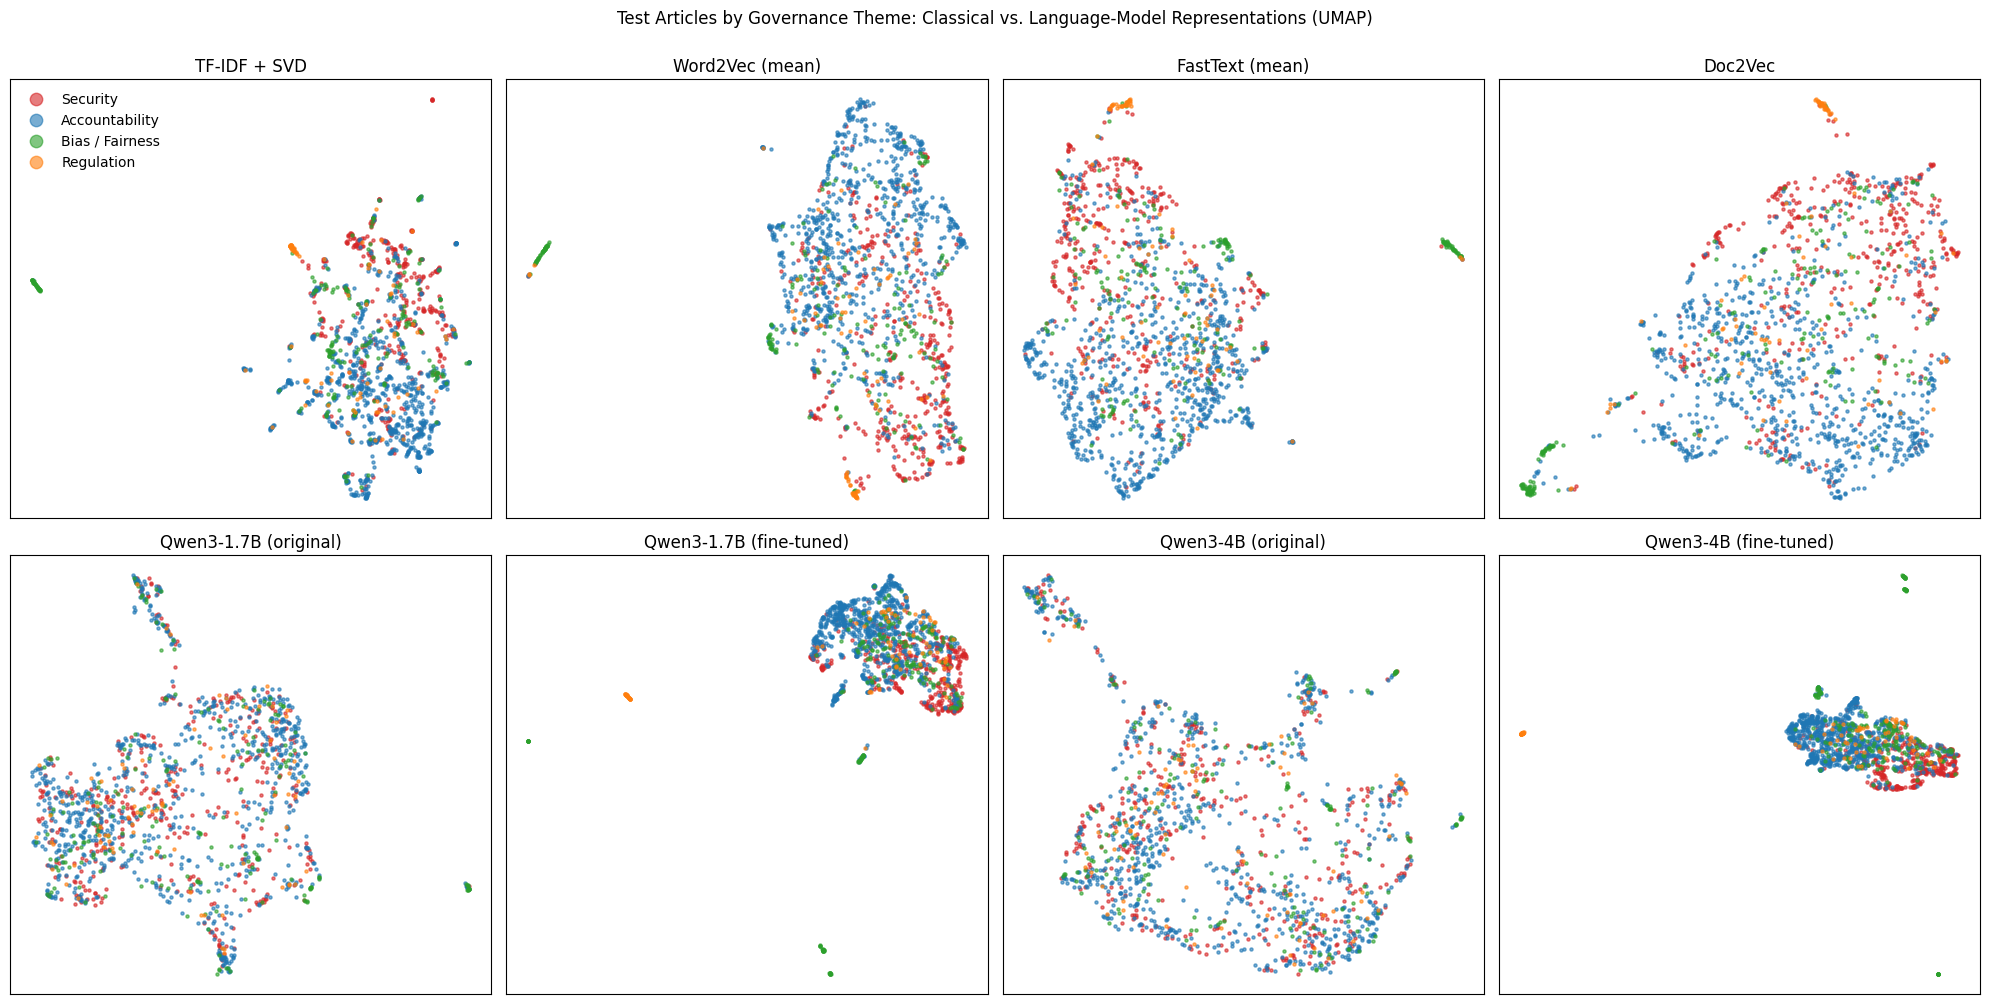

In [22]:
test_index = np.where(split_masks["test"])[0]
test_single = single_theme[test_index]
test_theme = single_theme_label[test_index][test_single]

test_representations = {
    "TF-IDF + SVD": doc_vectors["tfidf_svd"][test_index],
    "Word2Vec (mean)": doc_vectors["word2vec_mean"][test_index],
    "FastText (mean)": doc_vectors["fasttext_mean"][test_index],
    "Doc2Vec": doc_vectors["doc2vec"][test_index]
}
for name in LLM_MODELS:
    test_representations[f"{name} (original)"] = llm_predictions[name]["test_embeddings_base"]
    test_representations[f"{name} (fine-tuned)"] = llm_predictions[name]["test_embeddings_finetuned"]

representation_scores = pd.DataFrame({
    "Silhouette (Governance themes, test split)": {
        name: round(silhouette_score(normalize(matrix[test_single]), test_theme, metric="cosine"), 3)
        for name, matrix in test_representations.items()
    }
})
representation_scores.to_csv(RESULTS_DIR / "representation_silhouette.csv")
display(representation_scores)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, (name, matrix) in zip(axes.ravel(), test_representations.items()):
    coordinates = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED) \
        .fit_transform(normalize(matrix[test_single]))
    for theme_index, theme in enumerate(GOVERNANCE_THEMES):
        mask = test_theme == theme_index
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=5, alpha=0.6,
                   color=theme_colors[theme_index], label=THEME_LABELS[theme])
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].legend(markerscale=4, frameon=False)
fig.suptitle("Test Articles by Governance Theme: Classical vs. Language-Model Representations (UMAP)", y=1.0)
plt.tight_layout()
save_figure("representations_classical_vs_llm_umap")
plt.show()

**Observations**

All eight representations use the same held-out test articles and theme colours. Fine-tuning may improve theme separation without improving classification F1. The silhouette values measure this directly; the UMAP maps provide a qualitative view.


## 6. Insight Extraction for AI Governance

### 6.1 Governance Content Beyond the Tags

The theme classifiers distinguish themes within Governance coverage; they are not trained to decide whether an article is about Governance at all. We therefore use two steps:

1. A separate TF-IDF/logistic-regression relevance detector distinguishes tagged articles from noisy untagged negatives. Negative train/validation/test IDs are disjoint. Training negatives receive out-of-fold scores from pipelines fitted without that fold, including their TF-IDF step.
2. The **best model across all families, chosen by validation Macro-F1**, assigns themes to the resulting candidates. A more expensive language model is not preferred merely because it is a language model.

Untagged is not the same as irrelevant. The reported metrics measure separation of dataset tags, and the added articles remain unverified candidates.


In [23]:
import hashlib
import json

from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline

RELEVANCE_PATH = RESULTS_DIR / "relevance_v2_scores.csv"
RELEVANCE_META_PATH = RESULTS_DIR / "relevance_v2_meta.json"
RELEVANCE_CONFIG = {
    "version": 2, "seed": SEED, "negative_split": [0.70, 0.15, 0.15], "oof_folds": 5,
    "tfidf": {"ngram_range": (1, 2), "min_df": 5, "max_df": 0.8,
              "max_features": 50000, "sublinear_tf": True, "stop_words": "english"},
    "logreg": {"max_iter": 3000, "class_weight": "balanced", "C": 4.0},
}
relevance_fingerprint = hashlib.sha256(json.dumps(
    {"data": DATA_FINGERPRINT, "config": RELEVANCE_CONFIG}, sort_keys=True
).encode()).hexdigest()

positive_rows = {split: np.flatnonzero(corpus["split"].eq(split).to_numpy())
                 for split in ["train", "validation", "test"]}
untagged_index = np.flatnonzero(corpus["split"].eq("unlabelled").to_numpy())
negative_train, negative_holdout = train_test_split(
    untagged_index, test_size=0.30, random_state=SEED
)
negative_validation, negative_test = train_test_split(
    negative_holdout, test_size=0.50, random_state=SEED
)
negative_rows = {"train": negative_train, "validation": negative_validation, "test": negative_test}
assert len(np.unique(np.concatenate(list(negative_rows.values())))) == len(untagged_index)
parts = [("untagged", split, rows) for split, rows in negative_rows.items()]
parts += [(split, split, positive_rows[split]) for split in ["validation", "test"]]
expected = pd.concat([pd.DataFrame({
    "record_id": corpus["record_id"].iloc[rows].to_numpy(),
    "group": group, "relevance_split": split,
}) for group, split, rows in parts], ignore_index=True)

relevance = None
if RELEVANCE_PATH.exists() and RELEVANCE_META_PATH.exists():
    metadata = json.loads(RELEVANCE_META_PATH.read_text())
    if metadata.get("fingerprint") == relevance_fingerprint:
        cached = pd.read_csv(RELEVANCE_PATH)
        columns = ["record_id", "group", "relevance_split"]
        if (set(columns + ["score"]).issubset(cached.columns)
                and cached[columns].to_dict("list") == expected.to_dict("list")
                and cached["score"].between(0, 1).all()):
            relevance = cached
            print("Relevance v2 scores loaded from validated cache.")

if relevance is None:
    # Raw text keeps the detector independent of the corpus-wide phrase models.
    raw_texts = (corpus["title"].fillna("") + ". " + corpus["content_text"].fillna("")).to_numpy()

    def fit_detector(negative_training_rows):
        rows = np.r_[positive_rows["train"], negative_training_rows]
        labels = np.r_[np.ones(len(positive_rows["train"])), np.zeros(len(negative_training_rows))]
        detector = make_pipeline(
            TfidfVectorizer(**RELEVANCE_CONFIG["tfidf"]),
            LogisticRegression(**RELEVANCE_CONFIG["logreg"]),
        )
        return detector.fit(raw_texts[rows], labels)

    scores = np.full(len(corpus), np.nan)
    final_detector = fit_detector(negative_train)
    heldout = np.r_[negative_validation, negative_test,
                    positive_rows["validation"], positive_rows["test"]]
    scores[heldout] = final_detector.predict_proba(raw_texts[heldout])[:, 1]
    for fold, (train_part, score_part) in enumerate(KFold(
        n_splits=5, shuffle=True, random_state=SEED
    ).split(negative_train), start=1):
        detector = fit_detector(negative_train[train_part])
        rows = negative_train[score_part]
        scores[rows] = detector.predict_proba(raw_texts[rows])[:, 1]
        print(f"Relevance v2: negative training fold {fold}/5 scored.")
    relevance = expected.copy()
    relevance["score"] = np.concatenate([scores[rows] for _, _, rows in parts])
    assert relevance["record_id"].is_unique and np.isfinite(relevance["score"]).all()
    relevance.to_csv(RELEVANCE_PATH, index=False)
    RELEVANCE_META_PATH.write_text(json.dumps({
        "fingerprint": relevance_fingerprint, "data_fingerprint": DATA_FINGERPRINT,
        "config": RELEVANCE_CONFIG,
        "negative_counts": {split: len(rows) for split, rows in negative_rows.items()},
    }, indent=2))
    del detector, final_detector, raw_texts


def detection_holdout(split):
    positives = relevance.loc[relevance["group"].eq(split), "score"].to_numpy()
    negatives = relevance.loc[relevance["group"].eq("untagged")
                               & relevance["relevance_split"].eq(split), "score"].to_numpy()
    return np.r_[np.ones(len(positives)), np.zeros(len(negatives))], np.r_[positives, negatives]


y_validation_detect, validation_detect_scores = detection_holdout("validation")
threshold_grid = np.linspace(0.05, 0.95, 91)
RELEVANCE_THRESHOLD = float(threshold_grid[np.argmax([
    f1_score(y_validation_detect, validation_detect_scores >= threshold, zero_division=0)
    for threshold in threshold_grid
])])
y_detect, s_detect = detection_holdout("test")
candidate_ids = relevance.loc[relevance["group"].eq("untagged")
                              & relevance["score"].ge(RELEVANCE_THRESHOLD), "record_id"]
candidates = corpus.loc[corpus["record_id"].isin(candidate_ids)].merge(
    relevance.loc[relevance["group"].eq("untagged"), ["record_id", "score"]],
    on="record_id", validate="one_to_one",
).sort_values("score", ascending=False)
relevance_summary = pd.DataFrame({
    "Metric": ["ROC-AUC (held-out tagged vs. untagged test articles)",
               "Recall of tagged test articles", "Precision w.r.t. noisy dataset tags",
               "Validation-selected threshold", "Untagged articles", "Governance candidates"],
    "Result": [round(roc_auc_score(y_detect, s_detect), 3),
               round(recall_score(y_detect, s_detect >= RELEVANCE_THRESHOLD), 3),
               round(precision_score(y_detect, s_detect >= RELEVANCE_THRESHOLD, zero_division=0), 3),
               round(RELEVANCE_THRESHOLD, 2), len(untagged_index), len(candidate_ids)],
})
display(relevance_summary)
display(candidates[["record_id", "date", "domain", "title", "score"]].head(15))


Relevance v2 scores loaded from validated cache.


,Metric,Result
0,ROC-AUC (held-out tagged vs. untagged test art...,0.940
1,Recall of tagged test articles,0.766
2,Precision w.r.t. noisy dataset tags,0.814
3,Validation-selected threshold,0.530
4,Untagged articles,34733.000
5,Governance candidates,2670.000


,record_id,date,domain,title,score
2620,127706,2026-08-07,sciencenews,AI may respond differently to bosses and subor...,0.988724
1056,45811,2025-07-17,aijourn,Who Owns AI-Generated Creativity? Rethinking C...,0.988096
966,41455,2025-06-17,csis,Norms in New Technological Domains: What’s Nex...,0.986910
1112,81187,2025-08-01,bmj,Reporting guideline for chatbot health advice ...,0.982880
129,87682,2024-10-24,fintechweekly,Meet the Riskiest AI Models Ranked by Researchers,0.980742
14,155885,2024-09-15,webpronews,AI Compliance: What Every Chief Compliance Off...,0.979784
976,20424,2025-06-19,aithority,"In the Age of AI, Trust Is the Real Infrastruc...",0.979471
2344,144268,2026-06-02,thoughtworks,Lens four — Expanding impact of hostile tech,0.976352
2393,77042,2026-06-10,anthropic,Policy on the AI Exponential \ Anthropic,0.973511
140,41182,2024-10-28,csis,The Executive Action on Sensitive Bulk and Gov...,0.971597


**Observations**

These are held-out tag-recovery metrics using disjoint validation and test negatives. Untagged articles are only noisy negative proxies, so this does not estimate true Governance precision. Candidate titles and the saved manual-review sample help inspect obvious failures such as privacy-policy pages; human review has not been performed automatically.


### 6.2 Theme Assignment for the Candidate Articles

Use the model chosen on validation in Section 4.2 and its validation-tuned theme thresholds. The test scores are reported for context and do not influence this choice. The output includes the selected model name, prediction scores and a small blank manual-review sample.


In [24]:
best_thresholds = classification_thresholds[BEST_MODEL]
print(f"Theme classifier selected on validation: {BEST_MODEL}")
print(f"Held-out test Macro-F1 (reporting only): {final_results.loc[BEST_MODEL, 'Macro-F1']:.3f}")

candidate_order = candidates["record_id"].values
candidate_positions = pd.Index(corpus["record_id"]).get_indexer(candidate_order)
assert (candidate_positions >= 0).all()
if BEST_MODEL in classification_models:
    candidate_scores = predict_baseline(BEST_MODEL, [article_tokens[i] for i in candidate_positions])
else:
    best_llm_key = BEST_MODEL.replace(" (QLoRA)", "")
    old_path = RESULTS_DIR / f"candidate_theme_predictions_{best_llm_key}.csv"
    cached = pd.read_csv(old_path) if old_path.exists() else None
    if cached is not None and set(candidate_order).issubset(set(cached["record_id"])):
        candidate_scores = cached.set_index("record_id").loc[
            candidate_order, [f"score_{t}" for t in GOVERNANCE_THEMES]].values
    else:
        tokenizer, base_model = load_quantized_classifier(LLM_MODELS[best_llm_key])
        model = PeftModel.from_pretrained(base_model, MODELS_DIR / f"qlora_{best_llm_key}")
        candidate_scores = predict(model, tokenizer,
                                   (candidates["title"] + ". " + candidates["content_text"]).tolist())
        del model, base_model
        gc.collect()
        torch.cuda.empty_cache()

candidate_predictions = pd.DataFrame((candidate_scores >= best_thresholds).astype(int),
                                     columns=GOVERNANCE_THEMES)
candidate_predictions.insert(0, "record_id", candidate_order)
candidate_export = candidate_predictions.copy()
candidate_export["selected_model"] = BEST_MODEL
for k, theme in enumerate(GOVERNANCE_THEMES):
    candidate_export[f"score_{theme}"] = candidate_scores[:, k]
candidate_export.to_csv(RESULTS_DIR / "candidate_theme_predictions_selected_model.csv", index=False)

theme_extension = pd.DataFrame({
    "Tagged Governance articles": corpus.loc[corpus["governance_related"], GOVERNANCE_THEMES].sum(),
    "Additional candidates (predicted)": candidate_predictions[GOVERNANCE_THEMES].sum()
}).rename(index=THEME_LABELS)
theme_extension["Increase (%)"] = (
    theme_extension["Additional candidates (predicted)"] / theme_extension["Tagged Governance articles"] * 100
).round(1)
display(theme_extension)

# A review sample is a task for humans, not additional ground-truth labels.
review_sample = candidates[["record_id", "date", "domain", "title", "url", "score"]].head(20).copy()
review_sample["manual_governance_label"] = ""
review_sample["review_notes"] = ""
review_sample.to_csv(RESULTS_DIR / "candidate_manual_review_sample.csv", index=False)


Theme classifier selected on validation: TF-IDF (full) + LogReg
Held-out test Macro-F1 (reporting only): 0.739


,Tagged Governance articles,Additional candidates (predicted),Increase (%)
Security,4455,1160,26.0
Accountability,7592,1639,21.6
Bias / Fairness,2662,667,25.1
Regulation,1370,224,16.4


**Observations**

The table reports the additional theme counts predicted by the validation-selected model. These are candidate labels rather than verified missing annotations. Their distribution can reflect both missing tags and model errors.


### 6.3 Governance Trends With and Without the Candidates

If the tags systematically missed Governance coverage in some periods, adding the candidate articles would change the temporal development observed in Stage 1. The figure compares the monthly share of each Governance theme based on tags only with the share based on tags plus the predicted candidates.

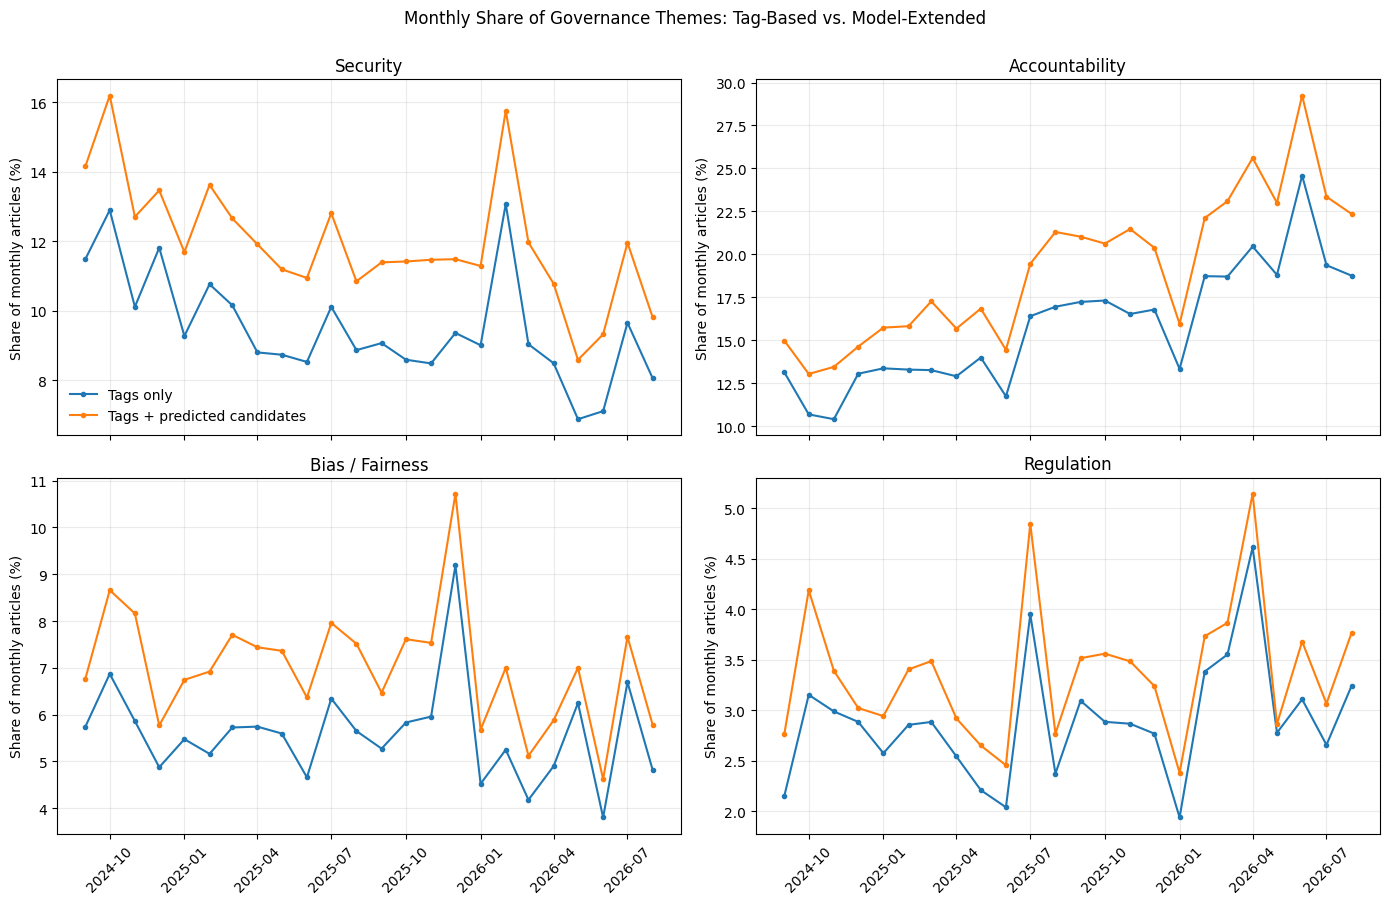

,Tags: first 3 months (%),Tags: last 3 months (%),Extended: first 3 months (%),Extended: last 3 months (%)
Security,11.50,8.28,14.35,10.37
Accountability,11.40,20.90,13.82,24.98
Bias / Fairness,6.16,5.11,7.86,6.02
Regulation,2.77,3.00,3.45,3.51


In [25]:
monthly = corpus[["record_id", "date"] + GOVERNANCE_THEMES].copy()
monthly = monthly[(monthly["date"] >= "2024-09-01") & (monthly["date"] <= "2026-08-31")]
monthly["month"] = monthly["date"].dt.to_period("M").dt.to_timestamp()

extended = monthly.set_index("record_id")[GOVERNANCE_THEMES].astype(int)
predicted = candidate_predictions.set_index("record_id")[GOVERNANCE_THEMES]
predicted = predicted[predicted.index.isin(extended.index)]
extended.loc[predicted.index] = extended.loc[predicted.index].values | predicted.values
extended["month"] = monthly.set_index("record_id")["month"]

total_per_month = monthly.groupby("month").size()
share_tags = monthly.groupby("month")[GOVERNANCE_THEMES].sum().div(total_per_month, axis=0) * 100
share_extended = extended.groupby("month")[GOVERNANCE_THEMES].sum().div(total_per_month, axis=0) * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, theme in zip(axes.ravel(), GOVERNANCE_THEMES):
    ax.plot(share_tags.index, share_tags[theme], marker="o", markersize=3, label="Tags only")
    ax.plot(share_extended.index, share_extended[theme], marker="o", markersize=3, label="Tags + predicted candidates")
    ax.set_title(THEME_LABELS[theme])
    ax.set_ylabel("Share of monthly articles (%)")
    ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Monthly Share of Governance Themes: Tag-Based vs. Model-Extended", y=1.0)
plt.tight_layout()
save_figure("governance_trends_tags_vs_model")
plt.show()

trend_comparison = pd.DataFrame({
    "Tags: first 3 months (%)": share_tags.iloc[:3].mean(),
    "Tags: last 3 months (%)": share_tags.iloc[-3:].mean(),
    "Extended: first 3 months (%)": share_extended.iloc[:3].mean(),
    "Extended: last 3 months (%)": share_extended.iloc[-3:].mean()
}).rename(index=THEME_LABELS).round(2)
display(trend_comparison)

**Observations**

The two sets of curves show sensitivity to this particular candidate-selection procedure. Similar trends support a limited robustness check, not a proof that every missing Governance article has been recovered. The final summary reports the current directions from the computed table.


## 7. Summary

The executable summary below is generated from this run so that the interpretation does not retain old scores after retraining.


In [26]:
best_row = final_results.loc[BEST_MODEL]
least_stable = semantic_shift.iloc[0]
most_separated = representation_scores.iloc[:, 0].idxmax()
direction_tags = np.sign(share_tags.iloc[-3:].mean() - share_tags.iloc[:3].mean())
direction_extended = np.sign(share_extended.iloc[-3:].mean() - share_extended.iloc[:3].mean())
display(Markdown(
    f"**Current run:** validation selects **{BEST_MODEL}** "
    f"(validation Macro-F1 {validation_results.loc[BEST_MODEL, 'Macro-F1']:.3f}; "
    f"held-out test Macro-F1 {best_row['Macro-F1']:.3f}). "
    f"The lowest period-neighbour overlap is **{least_stable['Term']}** "
    f"({least_stable['Neighbour overlap (Jaccard)']:.2f}). "
    f"The largest test-theme silhouette is obtained by **{most_separated}**. "
    f"The relevance detector proposes **{len(candidates):,}** untagged candidates. "
    f"The direction of the first-to-last three-month change agrees for "
    f"**{int((direction_tags == direction_extended).sum())}/4 themes** under this candidate procedure."
))
training_times_snapshot = {"embedding_cache_id": EMBEDDING_CACHE_ID, **training_times}
_ = (RESULTS_DIR / "training_times.json").write_text(json.dumps(training_times_snapshot, indent=2))

**Current run:** validation selects **TF-IDF (full) + LogReg** (validation Macro-F1 0.722; held-out test Macro-F1 0.739). The lowest period-neighbour overlap is **agent** (0.05). The largest test-theme silhouette is obtained by **Qwen3-4B (fine-tuned)**. The relevance detector proposes **2,670** untagged candidates. The direction of the first-to-last three-month change agrees for **4/4 themes** under this candidate procedure.

### Which representation is useful for the Governance track?

- Classification quality is judged on held-out articles. Specific law/regulator names can favour sparse TF-IDF, while averaged word embeddings describe broader semantic context.
- Word2Vec/FastText neighbours and the period models help interpret vocabulary and changing contexts. Their neighbour shifts are exploratory, not proof that word meaning itself changed.
- Fine-tuned Qwen representations can separate themes even when their classifier is not best. Their saved results use only 256 prefix tokens, so they do not establish the performance of a full-article language model.
- The candidate-extended trends are a sensitivity analysis with predicted labels. They do not replace manual annotation.

### Limitations

- Dataset tags are weak labels, and untagged articles are noisy negative proxies. The generated review sample has not been manually labelled.
- Only one training run per configuration is available. No statistical significance is claimed for small differences, and Gensim multi-worker training is not bit-for-bit deterministic.
- Classical models see full preprocessed articles, while saved Qwen runs see the prefix. The optional chunk experiment is separate; no chunking improvement is claimed without new validation/test results.
- CPU timings are local measurements; GPU timings come from earlier RTX 2000 Ada runs. Input coverage, preprocessing and hardware differ, which limits direct speed comparisons.
- The relevance training-negative scores are cross-fitted and the negative holdouts use the final train-only detector. These candidate scores come from slightly different training subsets.
- NMF-topic agreement is not independent human ground truth. UMAP and small curated word-pair tests are exploratory.

### Assignment coverage

| Requirement | Evidence in this notebook |
|---|---|
| Preprocessing and suitable splits | Article-level 70/15/15 splits, training-only phrase/embedding fit, split checks and cache identities |
| Classical embedding training | Word2Vec, FastText and Doc2Vec, plus period Word2Vec models |
| Compact open model adaptation | Annotated Qwen3-1.7B/4B QLoRA training code and clearly identified saved GPU results |
| Intrinsic evaluation | Word-pair similarity, nearest neighbours, common-test clustering/silhouette and UMAP |
| Extrinsic evaluation | Multi-label Governance classification; thresholds and model selection on validation |
| Size, speed and GPU trade-offs | Training-array/head sizes, measured training/inference times and peak GPU memory with provenance |
| Focused track insights | Validation-selected theme model, candidate review sample and temporal/vocabulary analysis |
| Chunking decision | Real tokenizer coverage analysis and a separately labelled optional inference experiment |

### Sources

- [Hugging Face tokenizer documentation](https://huggingface.co/docs/transformers/main/main_classes/tokenizer): truncation, overflow windows and overlap.
- [scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) and [validation-based threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html).

### Use of AI Tools

| AI tool | Use |
|---|---|
| Claude | Development, reviews and documentation |
| ChatGPT / Codex | Code review, debugging, methodological discussion, implementation and automatic checks |

The tables and plots are produced by the executed code. Modelling choices, weak-label limitations and the final interpretation are documented alongside the results.

## Contributions

- **Michael Nguyen** implemented and documented Stage 2.
- **Dana Srdic** and **Henrik Szent-Ivany** reviewed the notebook and contributed corrections and extensions.
